In [4]:
import os, base64, json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statistics import NormalDist
from sqlalchemy import create_engine
from pathlib import Path
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

BASE = "https://d1yyqbluk0oz0t.cloudfront.net"

In [5]:
# --- DuckDB + auth header for CloudFront -------------------------------
con = duckdb.connect("polymarket.duckdb")
con.execute("INSTALL httpfs; LOAD httpfs;")

load_dotenv()
env_path = Path.home() / ".env"
load_dotenv(dotenv_path=env_path)
token = base64.b64encode(
    f"{os.environ['STATS414_USERNAME']}:{os.environ['STATS414_PASSWORD']}".encode()
).decode()
con.execute(f"""
    CREATE OR REPLACE SECRET cloudfront_auth (
        TYPE http,
        EXTRA_HTTP_HEADERS MAP {{'Authorization': 'Basic {token}'}}
    )
""")

In [6]:
# --- Postgres (market metadata + resolutions) ---------------------------
engine = create_engine(os.environ["STATS414_URL"])
def q(sql):
    return pd.read_sql(sql, engine)

print("duckdb", duckdb.__version__)

duckdb 1.5.6


In [7]:
test_url = f"{BASE}/events-2026-05-30T21.parquet"
con.execute(f"SELECT COUNT(*) AS rows FROM read_parquet('{test_url}')").df()

,rows
0,20985641


In [8]:
counts = {t: int(q(f"SELECT COUNT(*) AS n FROM {t}").n[0]) for t in ["markets", "events", "resolutions"]}
pd.Series(counts, name="rows").to_frame()

,rows
markets,1513653
events,327432
resolutions,327762


In [9]:
mk = q("""
    SELECT slug, title, event_slug, best_bid, best_ask, volume_24hr, volume_1wk, volume_1mo,
           start_date, end_date, neg_risk
    FROM markets TABLESAMPLE BERNOULLI (2)
""")
mk["spread"] = mk.best_ask - mk.best_bid
mk["life_days"] = (pd.to_datetime(mk.end_date, utc=True) - pd.to_datetime(mk.start_date, utc=True)).dt.total_seconds() / 86400

pat = {
    "sports": r"\bvs\.?\b|spread|o/u|total games|handicap|map \d|\bwin on\b",
    "crypto": r"bitcoin|btc|ethereum|\beth\b|solana|crypto|\bprice of\b",
    "politics": r"election|trump|biden|president|senate|congress|nominee|ceasefire|prime minister",
}
def categorize(t):
    t = str(t).lower()
    for k, p in pat.items():
        if pd.Series([t]).str.contains(p, regex=True).iloc[0]:
            return k
    return "other"
mk["category"] = mk.title.map(categorize)
print(len(mk), "sampled markets")
mk.category.value_counts(normalize=True).round(3).to_frame("share of markets")

30255 sampled markets


,share of markets
category,
sports,0.517
other,0.392
crypto,0.080
politics,0.011


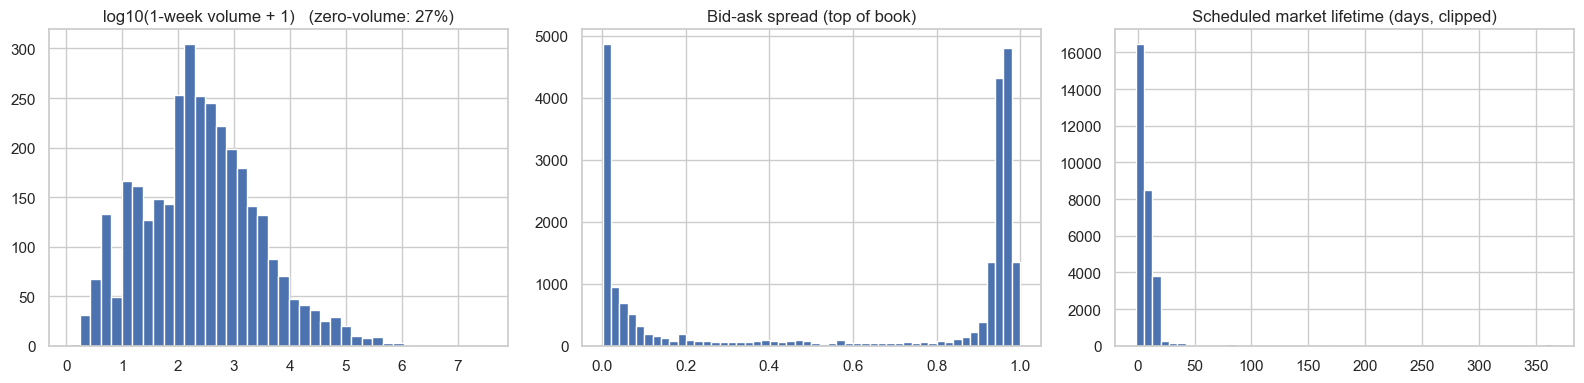

top 1% of markets = 87.9% of 1-week volume
top 10% of markets = 98.2% of 1-week volume


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

v = mk.volume_1wk.dropna()
ax[0].hist(np.log10(v[v > 0] + 1), bins=40)
ax[0].set_title(f"log10(1-week volume + 1)   (zero-volume: {(v == 0).mean():.0%})")

s = mk.spread.dropna()
s = s[(s >= 0) & (s <= 1)]
ax[1].hist(s, bins=50)
ax[1].set_title("Bid-ask spread (top of book)")

ax[2].hist(mk.life_days.clip(-5, 365).dropna(), bins=50)
ax[2].set_title("Scheduled market lifetime (days, clipped)")
plt.tight_layout(); plt.show()

# volume concentration: how much of weekly volume sits in the top 1% / 10% of markets?
vs = np.sort(v.values)[::-1]
for p in [0.01, 0.1]:
    print(f"top {p:.0%} of markets = {vs[: max(1, int(len(vs) * p))].sum() / vs.sum():.1%} of 1-week volume")

In [11]:
cat = (mk.groupby("category")
         .agg(markets=("slug", "count"), median_vol_1wk=("volume_1wk", "median"),
              total_vol_1wk=("volume_1wk", "sum"), median_spread=("spread", "median"))
         .sort_values("total_vol_1wk", ascending=False))
cat["share_of_volume"] = cat.total_vol_1wk / cat.total_vol_1wk.sum()
cat

,markets,median_vol_1wk,total_vol_1wk,median_spread,share_of_volume
category,,,,,
other,11848,112.428717,4.226615e+07,0.224,0.578874
sports,15644,28.414633,2.742831e+07,0.960,0.375656
crypto,2422,100.000000,2.533950e+06,0.010,0.034705
politics,341,335.964680,7.859417e+05,0.076,0.010764


In [12]:
q("""
    SELECT slug, title, volume_1wk, best_bid, best_ask, end_date
    FROM markets
    ORDER BY volume_1wk DESC NULLS LAST
    LIMIT 15
""")

,slug,title,volume_1wk,best_bid,best_ask,end_date
0,will-egypt-win-the-2026-fifa-world-cup,Will Egypt win the 2026 FIFA World Cup?,5.860876e+07,NaN,0.001,2026-07-20 00:00:00+00:00
1,us-x-iran-permanent-peace-deal-by-june-15-2026...,"US x Iran permanent peace deal by June 15, 2026?",4.781544e+07,0.8370,0.847,2026-06-15 00:00:00+00:00
2,fifwc-esp-arg-2026-07-19-team-to-advance,Spain vs. Argentina: Team to Advance,4.302373e+07,0.9975,1.000,2026-07-19 19:00:00+00:00
3,will-norway-win-the-2026-fifa-world-cup-893,Will Norway win the 2026 FIFA World Cup?,4.262494e+07,NaN,0.001,2026-07-20 00:00:00+00:00
4,will-argentina-win-the-2026-fifa-world-cup-245,Will Argentina win the 2026 FIFA World Cup?,4.245966e+07,NaN,0.001,2026-07-20 00:00:00+00:00
5,will-spain-win-the-2026-fifa-world-cup-963,Will Spain win the 2026 FIFA World Cup?,4.018375e+07,0.9990,1.000,2026-07-20 00:00:00+00:00
6,us-x-iran-permanent-peace-deal-by-may-31-2026-...,"US x Iran permanent peace deal by May 31, 2026?",3.941003e+07,0.0500,0.060,2026-05-31 00:00:00+00:00
7,will-mexico-win-the-2026-fifa-world-cup-529,Will Mexico win the 2026 FIFA World Cup?,3.910473e+07,NaN,0.001,2026-07-20 00:00:00+00:00
8,will-morocco-win-the-2026-fifa-world-cup-464,Will Morocco win the 2026 FIFA World Cup?,3.836068e+07,NaN,0.001,2026-07-20 00:00:00+00:00
9,will-switzerland-win-the-2026-fifa-world-cup,Will Switzerland win the 2026 FIFA World Cup?,3.802239e+07,NaN,0.001,2026-07-20 00:00:00+00:00


In [13]:
res = q("SELECT market_slug, resolved_yes, price_at_close, resolved_at, uma_resolution_status FROM resolutions")
res["resolved_at"] = pd.to_datetime(res.resolved_at, utc=True).dt.tz_localize(None)   # naive UTC, matches trade timestamps
print(f"{len(res):,} resolved markets | window {res.resolved_at.min()} -> {res.resolved_at.max()}")

con.register("res_df", res)
con.execute("CREATE OR REPLACE TABLE resolutions AS SELECT * FROM res_df")
con.unregister("res_df")

print("\nYes rate (base rate):", f"{res.resolved_yes.mean():.1%}")
print("price_at_close sanity (should be >=0.99 or <=0.01):",
      f"{((res.price_at_close >= 0.99) | (res.price_at_close <= 0.01)).mean():.1%}")
res.uma_resolution_status.value_counts(dropna=False).to_frame("markets")

327,800 resolved markets | window 2026-01-25 04:59:00 -> 2026-10-28 05:00:10.485942

Yes rate (base rate): 32.1%
price_at_close sanity (should be >=0.99 or <=0.01): 100.0%


,markets
uma_resolution_status,
resolved,327794
proposed,6


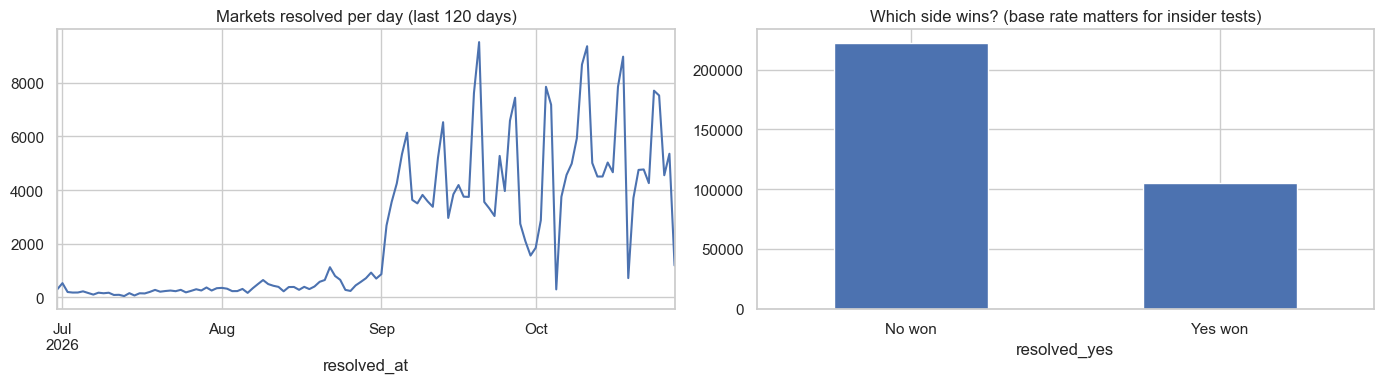

In [14]:
daily = res.set_index("resolved_at").resample("D").size()
daily = daily[daily.index >= daily.index.max() - pd.Timedelta(days=120)]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
daily.plot(ax=ax[0]); ax[0].set_title("Markets resolved per day (last 120 days)")
res.resolved_yes.value_counts().rename({True: "Yes won", False: "No won"}).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Which side wins? (base rate matters for insider tests)")
plt.tight_layout(); plt.show()

In [15]:
q("""
    SELECT COUNT(*) AS past_end_not_resolved
    FROM markets m
    WHERE m.end_date < now() AND m.end_date > now() - interval '30 days'
      AND NOT EXISTS (SELECT 1 FROM resolutions r WHERE r.market_slug = m.slug)
""")

,past_end_not_resolved
0,401125


In [16]:
TRADE_DATES = pd.date_range("2026-10-01", "2026-10-03").strftime("%Y-%m-%d").tolist()
trade_urls = [f"{BASE}/wallet_trades/trades-{d}.parquet" for d in TRADE_DATES]
url_list = ", ".join(f"'{u}'" for u in trade_urls)

print(con.execute(f"DESCRIBE SELECT * FROM read_parquet('{trade_urls[0]}')").df()[["column_name", "column_type"]])

for d, u in zip(TRADE_DATES, trade_urls):
    n = con.execute(f"SELECT COUNT(*) FROM read_parquet('{u}')").fetchone()[0]
    print(d, f"{n:,} fills")

  column_name               column_type
0      wallet                   VARCHAR
1      market                   VARCHAR
2        time  TIMESTAMP WITH TIME ZONE
3        side                   VARCHAR
4     outcome                   VARCHAR
5       price                    DOUBLE
6        size                    DOUBLE
7     dollars                    DOUBLE
2026-10-01 1,050,522 fills
2026-10-02 1,095,495 fills
2026-10-03 970,880 fills


In [17]:
con.execute("SET TimeZone = 'UTC'")

con.execute(f"""
    CREATE OR REPLACE TABLE trades_enriched AS
    SELECT t.wallet, t.market,
           CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP) AS ts,
           t.side, t.outcome, t.price, t.size, t.dollars,
           r.resolved_yes,
           CAST(r.resolved_at AS TIMESTAMP) AS resolved_at,
           (t.outcome = CASE WHEN r.resolved_yes THEN 'Yes' ELSE 'No' END) AS bet_on_winner,
           epoch(CAST(r.resolved_at AS TIMESTAMP)
                 - CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP)) / 3600.0 AS hrs_to_resolve
    FROM read_parquet([{url_list}]) t
    JOIN resolutions r ON r.market_slug = t.market
    WHERE t.outcome IN ('Yes', 'No')
""")
con.execute("""
    SELECT COUNT(*) AS fills, COUNT(DISTINCT wallet) AS wallets, COUNT(DISTINCT market) AS markets,
           SUM(dollars) AS total_dollars, MIN(ts) AS first_ts, MAX(ts) AS last_ts
    FROM trades_enriched
""").df()

,fills,wallets,markets,total_dollars,first_ts,last_ts
0,245147,19711,5226,2.763395e+07,2026-10-01 00:00:03,2026-10-03 23:59:59


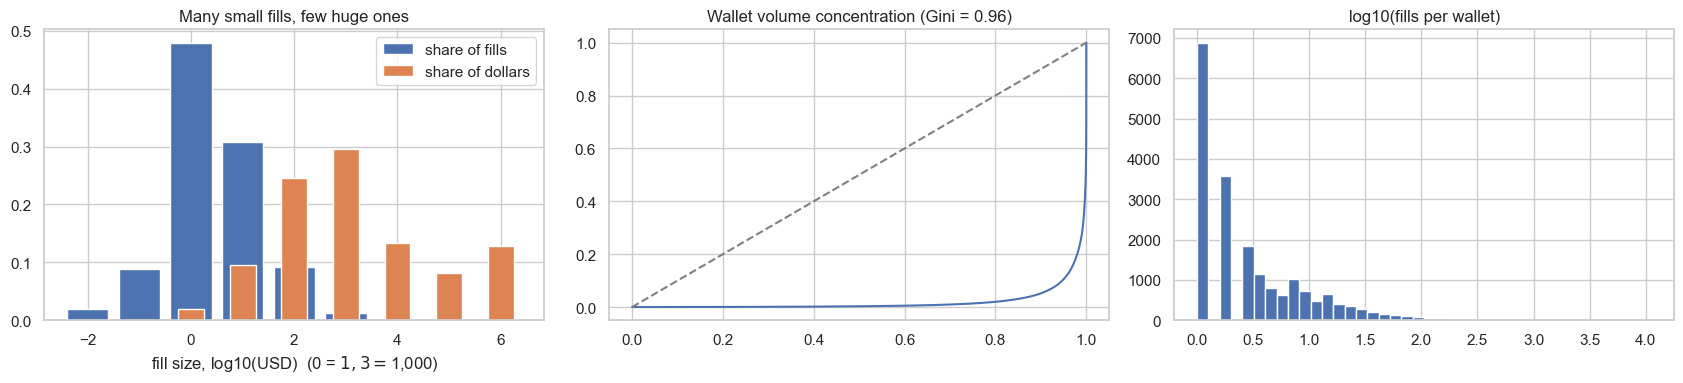

top 0.1% of wallets (19) = 47.7% of dollars
top 1.0% of wallets (197) = 72.6% of dollars
top 10.0% of wallets (1,971) = 94.8% of dollars


In [18]:
# Trade size: how many fills vs how many dollars sit in each size bucket
size = con.execute("""
    SELECT FLOOR(LOG10(GREATEST(dollars, 0.01))) AS log10_usd,
           COUNT(*) AS fills, SUM(dollars) AS dollars
    FROM trades_enriched GROUP BY 1 ORDER BY 1
""").df()
size["fills_share"] = size.fills / size.fills.sum()
size["dollars_share"] = size.dollars / size.dollars.sum()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].bar(size.log10_usd, size.fills_share, width=0.8, label="share of fills")
ax[0].bar(size.log10_usd, size.dollars_share, width=0.5, label="share of dollars")
ax[0].set_xlabel("fill size, log10(USD)  (0 = $1, 3 = $1,000)"); ax[0].legend(); ax[0].set_title("Many small fills, few huge ones")

wv = con.execute("""
    SELECT wallet, SUM(dollars) AS dollars, COUNT(*) AS fills, COUNT(DISTINCT market) AS markets
    FROM trades_enriched GROUP BY wallet
""").df().sort_values("dollars", ascending=False).reset_index(drop=True)

# Lorenz curve + Gini
x = np.sort(wv.dollars.values); cum = np.cumsum(x) / x.sum()
ax[1].plot(np.linspace(0, 1, len(cum)), cum); ax[1].plot([0, 1], [0, 1], "--", color="gray")
n = len(x); gini = 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n
ax[1].set_title(f"Wallet volume concentration (Gini = {gini:.2f})")

ax[2].hist(np.log10(wv.fills), bins=40); ax[2].set_title("log10(fills per wallet)")
plt.tight_layout(); plt.show()

for p in [0.001, 0.01, 0.1]:
    k = max(1, int(len(wv) * p))
    print(f"top {p:.1%} of wallets ({k:,}) = {wv.dollars.iloc[:k].sum() / wv.dollars.sum():.1%} of dollars")

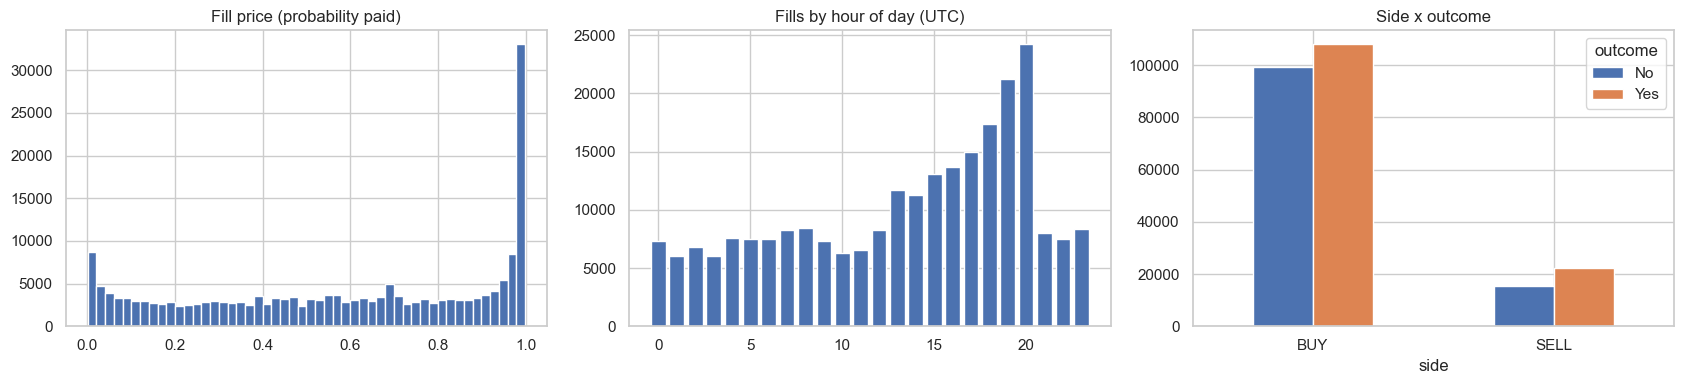

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

pr = con.execute("SELECT price FROM trades_enriched USING SAMPLE 200000 ROWS").df()
ax[0].hist(pr.price, bins=50); ax[0].set_title("Fill price (probability paid)")

hr = con.execute("SELECT EXTRACT(hour FROM ts) AS hr, COUNT(*) AS fills, SUM(dollars) AS usd FROM trades_enriched GROUP BY 1 ORDER BY 1").df()
ax[1].bar(hr.hr, hr.fills); ax[1].set_title("Fills by hour of day (UTC)")

mix = con.execute("SELECT side, outcome, COUNT(*) AS fills FROM trades_enriched GROUP BY 1, 2").df()
mix.pivot(index="side", columns="outcome", values="fills").plot.bar(ax=ax[2], rot=0); ax[2].set_title("Side x outcome")
plt.tight_layout(); plt.show()

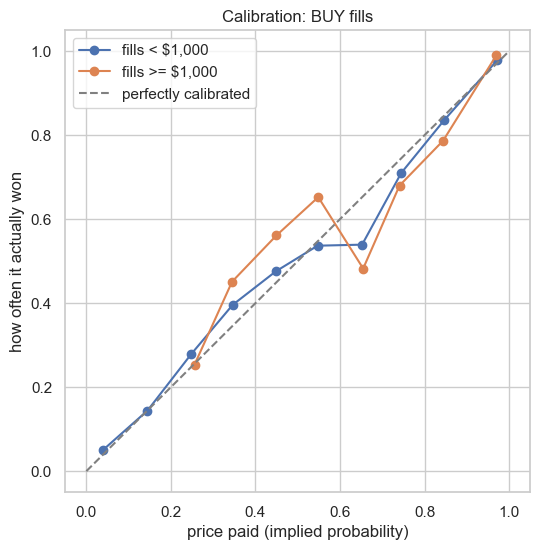

,bucket,big,fills,implied_prob,actual_win_rate
0,0.0,False,21136,0.039705,0.050719
1,0.1,False,14528,0.144573,0.144204
2,0.2,False,14542,0.248512,0.279260
3,0.3,False,14363,0.346202,0.396018
4,0.4,False,18031,0.448086,0.475625
5,0.5,False,18340,0.547076,0.536859
6,0.6,False,19621,0.652310,0.539320
7,0.7,False,15508,0.744947,0.710021
8,0.8,False,16682,0.846623,0.835871
9,0.9,False,51670,0.972444,0.979059


In [20]:
cal = con.execute("""
    SELECT FLOOR(price * 10) / 10 AS bucket,
           (dollars >= 1000) AS big,
           COUNT(*) AS fills,
           AVG(price) AS implied_prob,
           AVG(bet_on_winner::INT) AS actual_win_rate
    FROM trades_enriched
    WHERE side = 'BUY'
    GROUP BY 1, 2
    HAVING COUNT(*) >= 30
    ORDER BY 2, 1
""").df()

plt.figure(figsize=(6, 6))
for big, g in cal.groupby("big"):
    plt.plot(g.implied_prob, g.actual_win_rate, "o-", label="fills >= $1,000" if big else "fills < $1,000")
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfectly calibrated")
plt.xlabel("price paid (implied probability)"); plt.ylabel("how often it actually won"); plt.legend()
plt.title("Calibration: BUY fills"); plt.show()
cal

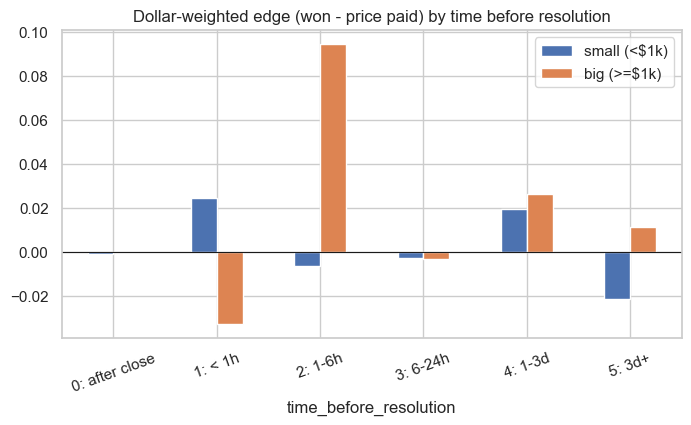

,time_before_resolution,big,fills,dollars,dollar_weighted_edge
0,0: after close,False,2,2.000000e+00,-0.001000
1,1: < 1h,False,3964,1.937470e+05,0.024433
2,1: < 1h,True,89,2.853708e+05,-0.032628
3,2: 1-6h,False,87304,4.756831e+06,-0.006419
4,2: 1-6h,True,2028,9.549392e+06,0.094576
5,3: 6-24h,False,62527,2.026412e+06,-0.002811
6,3: 6-24h,True,532,1.890678e+06,-0.003344
7,4: 1-3d,False,32473,6.685294e+05,0.019502
8,4: 1-3d,True,84,2.444805e+05,0.026407
9,5: 3d+,False,18151,7.942543e+05,-0.021396


In [21]:
timing = con.execute("""
    SELECT CASE WHEN hrs_to_resolve < 0   THEN '0: after close'
                WHEN hrs_to_resolve < 1   THEN '1: < 1h'
                WHEN hrs_to_resolve < 6   THEN '2: 1-6h'
                WHEN hrs_to_resolve < 24  THEN '3: 6-24h'
                WHEN hrs_to_resolve < 72  THEN '4: 1-3d'
                ELSE '5: 3d+' END AS time_before_resolution,
           (dollars >= 1000) AS big,
           COUNT(*) AS fills,
           SUM(dollars) AS dollars,
           SUM(dollars * (bet_on_winner::INT - price)) / SUM(dollars) AS dollar_weighted_edge
    FROM trades_enriched
    WHERE side = 'BUY'
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()

piv = timing.pivot(index="time_before_resolution", columns="big", values="dollar_weighted_edge")
piv.columns = ["small (<$1k)", "big (>=$1k)"][: len(piv.columns)]
piv.plot.bar(rot=20, figsize=(8, 4)); plt.axhline(0, color="k", lw=0.8)
plt.title("Dollar-weighted edge (won - price paid) by time before resolution"); plt.show()
timing

In [22]:
con.execute("""
    CREATE OR REPLACE TABLE positions AS
    SELECT wallet, market, outcome,
           SUM(CASE WHEN side = 'BUY'  THEN size    ELSE 0 END) AS buy_shares,
           SUM(CASE WHEN side = 'SELL' THEN size    ELSE 0 END) AS sell_shares,
           SUM(CASE WHEN side = 'BUY'  THEN dollars ELSE 0 END) AS buy_usd,
           SUM(CASE WHEN side = 'SELL' THEN dollars ELSE 0 END) AS sell_usd,
           MAX(bet_on_winner::INT) AS won,
           MIN(hrs_to_resolve) AS min_hrs_to_resolve,
           COUNT(*) AS fills
    FROM trades_enriched
    GROUP BY wallet, market, outcome
""")

# window-limited P&L: payout is $1 per net share if the outcome won
con.execute("""
    CREATE OR REPLACE TABLE positions2 AS
    SELECT *, won * (buy_shares - sell_shares) - buy_usd + sell_usd AS pnl,
           buy_usd / NULLIF(buy_shares, 0) AS vwap
    FROM positions
""")

MIN_POSITIONS = 10   # ignore wallets with too few independent bets

con.execute(f"""
    CREATE OR REPLACE TABLE wallet_stats AS
    SELECT wallet,
           COUNT(*) AS n_positions,
           COUNT(DISTINCT market) AS n_markets,
           SUM(buy_usd) AS buy_usd,
           SUM(won) AS wins,
           SUM(vwap) AS expected_wins,
           (SUM(won) - SUM(vwap)) / SQRT(SUM(vwap * (1 - vwap))) AS z,
           SUM(pnl) / SUM(buy_usd) AS roi,
           SUM(pnl) AS pnl
    FROM positions2
    WHERE buy_shares > 0 AND sell_shares <= 0.1 * buy_shares AND vwap > 0 AND vwap < 1
    GROUP BY wallet
    HAVING COUNT(*) >= {MIN_POSITIONS}
""")
ws = con.execute("SELECT * FROM wallet_stats").df()
print(f"{len(ws):,} wallets with >= {MIN_POSITIONS} directional positions")

1,460 wallets with >= 10 directional positions


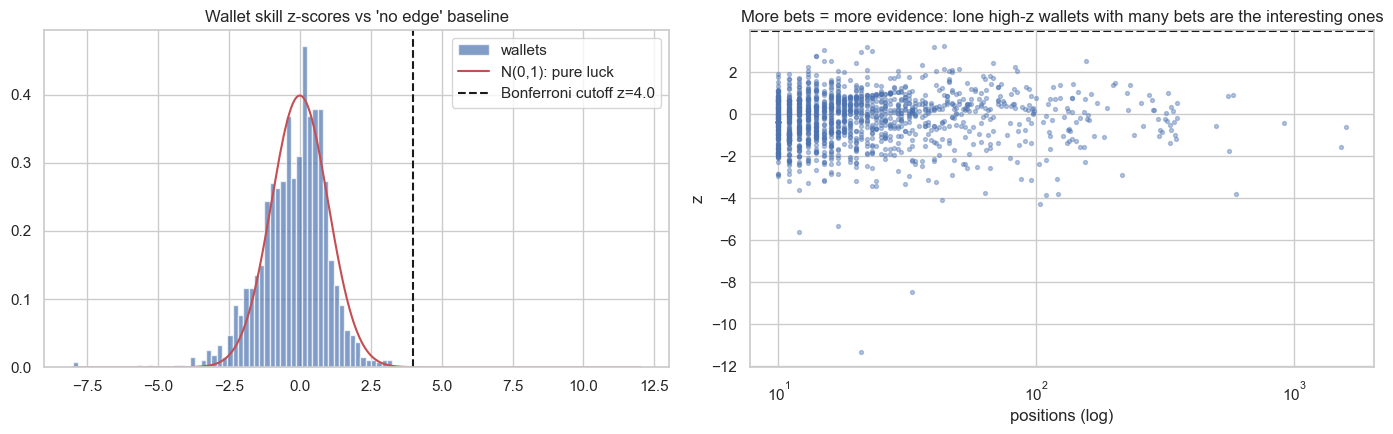

0 wallets above the Bonferroni cutoff


,wallet,n_positions,n_markets,buy_usd,wins,expected_wins,z,roi,pnl
141,0xa8125f700762b560e0e2a42a10781e27cb87bfc2,44,43,211.261,32.0,23.984,3.259,0.590,124.576
995,0x29eaa753365e8e9ec878602755452859ea0d3ef8,22,22,7740.663,22.0,20.973,3.220,3.880,30030.136
603,0x432aa1018b5745cdcb70211eeb32477592a16bdd,40,39,2970.925,32.0,23.161,3.204,0.359,1065.190
870,0x1bc9fe2ec65f49f91c97210215d34aa4f9f5e6e6,15,14,895.283,14.0,9.069,3.046,0.202,181.167
531,0xb6917f682157bbaffcc7123a2bbd7c58c3ba4ea2,23,23,4937.003,22.0,15.790,3.025,0.663,3272.714
333,0xa3f442a52d54e78c0bc8555ad3a7a023568b0638,21,21,3501.735,18.0,12.239,2.961,0.742,2598.312
1048,0xf97d955ce72b1c0a685416c9d06d7cafb6379abd,14,14,70.000,13.0,8.420,2.762,0.731,51.183
1150,0xcbb3a557dea80b32c7c3a0f081e21cc765a83a13,14,14,59.511,12.0,7.783,2.761,0.714,42.494
160,0xad84f15bd05708d5dd034a98f39bfeb99f4d3b0a,16,16,82.000,15.0,10.535,2.523,0.474,38.881
1190,0xdc87be4cbd1bdec640e7a4d9c7e7cf420d5d751b,156,119,3389.217,94.0,80.247,2.517,0.226,764.696


In [23]:
nd = NormalDist()
bonf = nd.inv_cdf(1 - 0.05 / max(len(ws), 1))      # threshold after correcting for testing many wallets

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(ws.z.clip(-8, 12), bins=60, density=True, alpha=0.7, label="wallets")
xs = np.linspace(-8, 12, 300)
ax[0].plot(xs, [nd.pdf(v) for v in xs], "r-", label="N(0,1): pure luck")
ax[0].axvline(bonf, ls="--", color="k", label=f"Bonferroni cutoff z={bonf:.1f}")
ax[0].set_title("Wallet skill z-scores vs 'no edge' baseline"); ax[0].legend()

ax[1].scatter(ws.n_positions, ws.z, s=8, alpha=0.4); ax[1].set_xscale("log")
ax[1].axhline(bonf, ls="--", color="k"); ax[1].set_xlabel("positions (log)"); ax[1].set_ylabel("z")
ax[1].set_title("More bets = more evidence: lone high-z wallets with many bets are the interesting ones")
plt.tight_layout(); plt.show()

print(f"{(ws.z > bonf).sum()} wallets above the Bonferroni cutoff")
ws.sort_values("z", ascending=False).head(20).round(3)

In [24]:
LONGSHOT_PRICE = 0.20     # market thought it was <= 20% likely
BIG_USD = 1000

feat = con.execute(f"""
    SELECT wallet,
           SUM(CASE WHEN side='BUY' AND price <= {LONGSHOT_PRICE} AND bet_on_winner AND dollars >= {BIG_USD}
                    THEN dollars ELSE 0 END) AS longshot_win_usd,
           SUM(CASE WHEN side='BUY' AND hrs_to_resolve BETWEEN 0 AND 6 THEN dollars ELSE 0 END)
               / NULLIF(SUM(CASE WHEN side='BUY' THEN dollars ELSE 0 END), 0) AS share_buy_usd_last6h
    FROM trades_enriched GROUP BY wallet
""").df()

top_mkt = con.execute("""
    SELECT wallet, MAX(usd) / SUM(usd) AS top_market_share
    FROM (SELECT wallet, market, SUM(dollars) AS usd FROM trades_enriched GROUP BY 1, 2)
    GROUP BY wallet
""").df()

wf = (ws.merge(feat, on="wallet").merge(top_mkt, on="wallet"))
wf["flag_skill"]      = wf.z > bonf
wf["flag_longshot"]   = wf.longshot_win_usd > 0
wf["flag_late"]       = wf.share_buy_usd_last6h > 0.5
wf["flag_concentrated"] = (wf.top_market_share > 0.5) & (wf.buy_usd >= BIG_USD)
flags = [c for c in wf.columns if c.startswith("flag_")]
wf["n_flags"] = wf[flags].sum(axis=1)

print(wf.n_flags.value_counts().sort_index().to_frame("wallets"))
wf.sort_values(["n_flags", "z"], ascending=False).head(25)[
    ["wallet", "n_positions", "n_markets", "buy_usd", "z", "roi", "longshot_win_usd",
     "share_buy_usd_last6h", "top_market_share", "n_flags"]].round(3)

         wallets
n_flags         
0            909
1            534
2             17


,wallet,n_positions,n_markets,buy_usd,z,roi,longshot_win_usd,share_buy_usd_last6h,top_market_share,n_flags
1167,0x3415db766f82fe1905762d3b8a9ec0aa062c1d11,11,11,3980.920,1.670,0.434,0.0,1.000,0.638,2
434,0x10e9872519aa6d049fce4f52f1b864d81583ab5f,14,13,5898.679,0.394,0.014,0.0,1.000,0.508,2
246,0x416d21b8aa562b86b01d0153915634a04d693f0d,31,31,22166.019,0.389,0.023,0.0,1.000,0.806,2
1274,0xef25ec91dd476f142e42e1f7db44d7c755ea4308,10,7,26321.102,0.241,-0.236,0.0,1.000,0.614,2
882,0x69a094fb385bcaf83f60eef4a3cf1a2efc94b784,13,13,1195.117,0.241,0.007,0.0,0.726,0.590,2
504,0x8be881588ee32d0905566d2634e9767dbe6e5bee,16,9,7248.172,0.237,0.123,0.0,0.973,0.576,2
455,0x1d1293eec514bf02a083630f07175e97b2886535,18,18,3778.671,0.149,0.001,0.0,1.000,0.571,2
665,0xfa0cba1c36c7cddb804279a5d0d24577076512c9,10,7,4770.067,-0.162,0.322,0.0,1.000,0.752,2
304,0xfd182dc0770a6426a301b56fdbdb709a0de9a81d,11,11,13125.237,-0.177,0.027,0.0,0.988,0.970,2
731,0x73a00c93a7c70f12ccfad13ed7f11693fe5108b1,11,11,2305.120,-0.744,-0.368,0.0,0.919,0.537,2


61,744 assets in snapshot | empty books: 25597 | crossed books (bid >= ask): 441


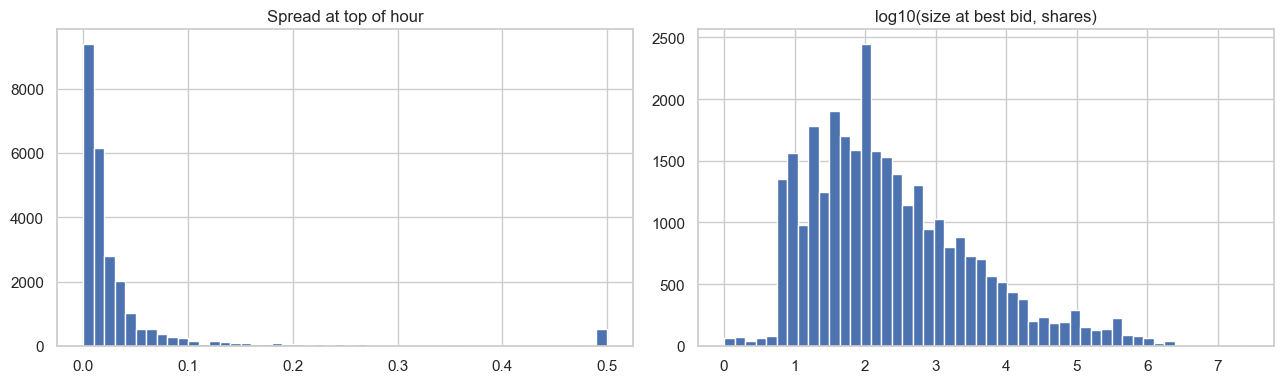

In [25]:
OB_HOUR = "2026-10-02T15"
snap_url   = f"{BASE}/snap-{OB_HOUR}.parquet"
events_url = f"{BASE}/events-{OB_HOUR}.parquet"

snap = con.execute(f"""
    SELECT asset_id,
           bids[1].price AS best_bid, asks[1].price AS best_ask,
           len(bids) AS bid_levels, len(asks) AS ask_levels,
           bids[1].size AS best_bid_size, asks[1].size AS best_ask_size
    FROM read_parquet('{snap_url}')
""").df()
snap["spread"] = snap.best_ask - snap.best_bid
print(f"{len(snap):,} assets in snapshot | empty books: {(snap.bid_levels + snap.ask_levels == 0).sum()} | "
      f"crossed books (bid >= ask): {(snap.spread <= 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(snap.spread.dropna().clip(0, 0.5), bins=50); ax[0].set_title("Spread at top of hour")
ax[1].hist(np.log10(snap.best_bid_size.dropna() + 1), bins=50); ax[1].set_title("log10(size at best bid, shares)")
plt.tight_layout(); plt.show()

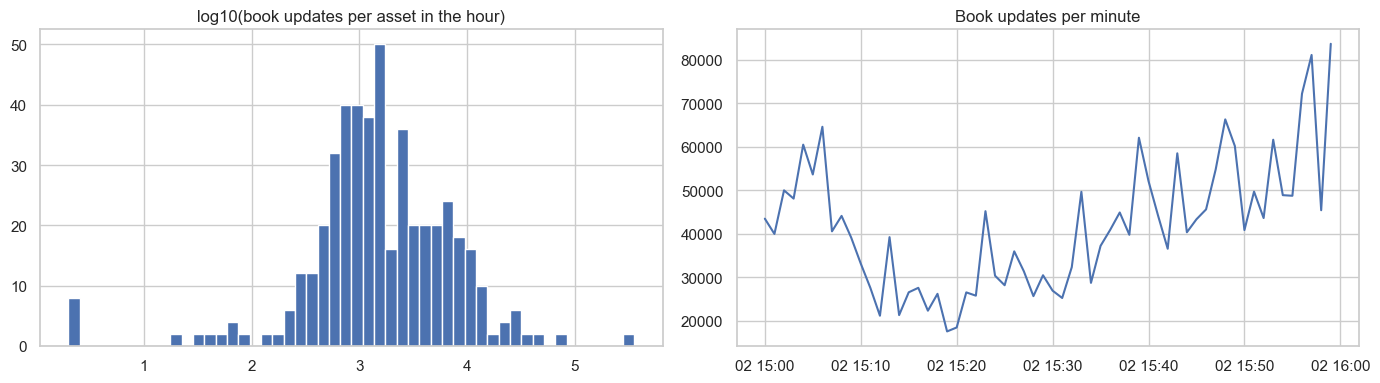

476 assets updated | busiest asset: 355,608 updates | median: 1,394 | removals (size=0): 18.5%


In [26]:
per_asset = con.execute(f"""
    SELECT asset_id, COUNT(*) AS events, AVG((size = 0)::INT) AS removal_share
    FROM read_parquet('{events_url}') GROUP BY asset_id
""").df().sort_values("events", ascending=False)

per_min = con.execute(f"""
    SELECT to_timestamp((ts_ms // 60000) * 60) AS minute, COUNT(*) AS events
    FROM read_parquet('{events_url}') GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(np.log10(per_asset.events), bins=50); ax[0].set_title("log10(book updates per asset in the hour)")
ax[1].plot(per_min.minute, per_min.events); ax[1].set_title("Book updates per minute")
plt.tight_layout(); plt.show()
print(f"{len(per_asset):,} assets updated | busiest asset: {per_asset.events.iloc[0]:,} updates | "
      f"median: {per_asset.events.median():,.0f} | removals (size=0): {per_asset.removal_share.mean():.1%}")

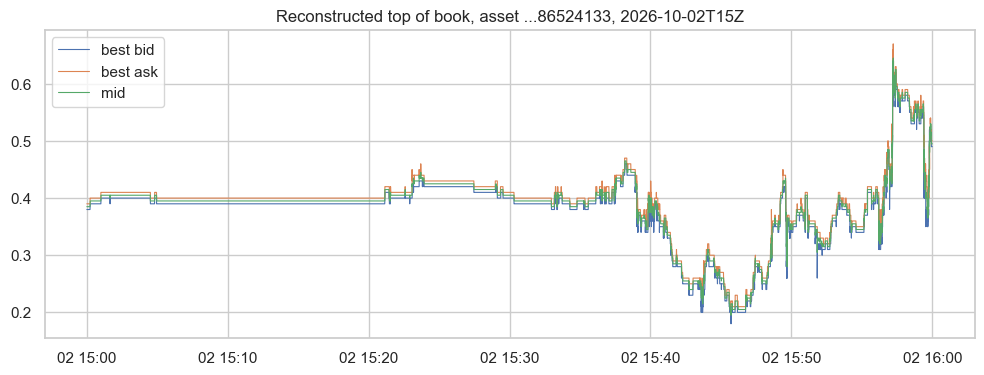

In [27]:
def reconstruct_top_of_book(asset_id):
    s = con.execute(f"SELECT bids, asks FROM read_parquet('{snap_url}') WHERE asset_id = ?", [asset_id]).df()
    bids = {float(l["price"]): float(l["size"]) for l in (s.bids.iloc[0] if len(s) else [])}
    asks = {float(l["price"]): float(l["size"]) for l in (s.asks.iloc[0] if len(s) else [])}
    ev = con.execute(f"""
        SELECT ts_ms, side, price, size FROM read_parquet('{events_url}')
        WHERE asset_id = ? ORDER BY ts_ms
    """, [asset_id]).df()
    out = []
    for ts, side, price, size in ev.itertuples(index=False):
        book = bids if side == "BUY" else asks
        if size == 0: book.pop(price, None)
        else:         book[price] = size
        out.append((ts, max(bids) if bids else np.nan, min(asks) if asks else np.nan))
    df = pd.DataFrame(out, columns=["ts_ms", "best_bid", "best_ask"])
    df["ts"] = pd.to_datetime(df.ts_ms, unit="ms")
    df["mid"] = (df.best_bid + df.best_ask) / 2
    return df

asset = per_asset.asset_id.iloc[0]
tob = reconstruct_top_of_book(asset)
plt.figure(figsize=(12, 4))
plt.plot(tob.ts, tob.best_bid, label="best bid", lw=0.8); plt.plot(tob.ts, tob.best_ask, label="best ask", lw=0.8)
plt.plot(tob.ts, tob.mid, label="mid", lw=0.8); plt.legend(); plt.title(f"Reconstructed top of book, asset ...{asset[-8:]}, {OB_HOUR}Z")
plt.show()

In [28]:
gaps = pd.DataFrame({
    "gap_start": ["2026-06-16T11", "2026-08-25T00", "2026-09-14T01"],
    "gap_end":   ["2026-06-19T19", "2026-08-31T14", "2026-09-14T15"],
    "hours":     [80, 158, 14],
})
total_hours = int((pd.Timestamp("2026-10-05") - pd.Timestamp("2026-05-30")).total_seconds() // 3600)
print(f"{gaps.hours.sum()} missing hours out of ~{total_hours} -> {gaps.hours.sum() / total_hours:.1%} of the order book timeline is missing")
gaps

252 missing hours out of ~3072 -> 8.2% of the order book timeline is missing


,gap_start,gap_end,hours
0,2026-06-16T11,2026-06-19T19,80
1,2026-08-25T00,2026-08-31T14,158
2,2026-09-14T01,2026-09-14T15,14


In [29]:
from sqlalchemy import text
import json

q(text("""
    SELECT split_part(slug, '-', 1) AS prefix, COUNT(*) AS markets,
           MIN(end_date) AS first_end, MAX(end_date) AS last_end
    FROM markets
    WHERE slug LIKE 'fifwc-%' OR slug LIKE '%world-cup%'
    GROUP BY 1 ORDER BY markets DESC LIMIT 20
"""))

,prefix,markets,first_end,last_end
0,fifwc,16699,2026-06-11 19:00:00+00:00,2026-07-19 19:00:00+00:00
1,will,2584,2026-05-30 00:00:00+00:00,2030-07-22 03:59:00+00:00
2,world,28,2026-07-20 00:00:00+00:00,2026-10-07 03:59:00+00:00
3,2026,1,2026-06-29 00:00:00+00:00,2026-06-29 00:00:00+00:00
4,ill,1,2026-07-20 00:00:00+00:00,2026-07-20 00:00:00+00:00
5,president,1,2026-07-20 03:59:00+00:00,2026-07-20 03:59:00+00:00


In [30]:
wc = q(text("""
    SELECT slug, title, event_slug, outcomes, end_date
    FROM markets
    WHERE slug LIKE 'fifwc-%' OR slug LIKE '%2026-fifa-world-cup%'
"""))
wc["end_date"] = pd.to_datetime(wc.end_date, utc=True).dt.tz_localize(None)
print(len(wc), "World Cup markets")

18315 World Cup markets


In [31]:
wc["outcomes"] = wc.outcomes.map(lambda x: json.loads(x) if isinstance(x, str) else x)
wc = wc.merge(res[["market_slug", "resolved_yes", "resolved_at"]],
              left_on="slug", right_on="market_slug", how="left")

def winner(r):
    if pd.isna(r.resolved_yes) or len(r.outcomes) < 2:
        return None
    return r.outcomes[0] if bool(r.resolved_yes) else r.outcomes[1]

wc["winner_label"] = wc.apply(winner, axis=1)
wc["kind"] = np.where(wc.slug.str.startswith("fifwc-"), "match", "outright/other")

# Eyeball this against results you know (e.g. the final)
print(wc[wc.winner_label.notna()][["slug", "outcomes", "resolved_yes", "winner_label"]].sample(8))

wc_all = wc[["slug", "title", "event_slug", "kind", "end_date", "winner_label", "resolved_at"]]
con.register("wc_df", wc_all)
con.execute("CREATE OR REPLACE TABLE wc_markets AS SELECT * FROM wc_df")
con.unregister("wc_df")
con.execute("SELECT kind, COUNT(*) AS markets, COUNT(winner_label) AS resolved FROM wc_markets GROUP BY 1").df()

                                                    slug   outcomes resolved_yes winner_label
775             fifwc-bra-hai-2026-06-19-exact-score-1-2  [Yes, No]        False           No
14682    fifwc-sco-mar-2026-06-19-goals-brahim-diaz-gte2  [Yes, No]        False           No
14986  fifwc-bra-hai-2026-06-19-shots-matheus-cunha-gte3  [Yes, No]        False           No
1478                        fifwc-arg-alg-2026-06-16-arg  [Yes, No]         True          Yes
1881      fifwc-hai-sco-2026-06-13-exact-score-any-other  [Yes, No]        False           No
13372  fifwc-irq-nor-2026-06-16-goals-plus-assists-al...  [Yes, No]        False           No
1960       fifwc-jor-arg-2026-06-27-halftime-result-home  [Yes, No]        False           No
386             fifwc-eng-hrv-2026-06-17-exact-score-1-0  [Yes, No]        False           No


,kind,markets,resolved
0,outright/other,1616,531
1,match,16699,3864


In [32]:
con.execute("DROP TABLE IF EXISTS wc_trades")
con.execute("DROP TABLE IF EXISTS wc_loaded_days")

In [33]:
con.execute("SET TimeZone = 'UTC'")
con.execute("CREATE TABLE IF NOT EXISTS wc_loaded_days (day VARCHAR)")
done = {r[0] for r in con.execute("SELECT day FROM wc_loaded_days").fetchall()}
have_table = con.execute(
    "SELECT COUNT(*) FROM information_schema.tables WHERE table_name = 'wc_trades'").fetchone()[0] > 0

# Outrights trade for months before kickoff. Start with a week, then widen
# (e.g. "2026-05-30" -> "2026-07-21"). Days with no file are skipped and printed.
FIRST_DAY, LAST_DAY = "2026-06-01", "2026-10-05"

for d in pd.date_range(FIRST_DAY, LAST_DAY).strftime("%Y-%m-%d"):
    if d in done:
        continue
    url = f"{BASE}/wallet_trades/trades-{d}.parquet"
    sql = f"""
        SELECT t.wallet, t.market, m.kind, m.event_slug, m.end_date,
               CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP) AS ts,
               t.side, t.outcome, t.price, t.size, t.dollars,
               (t.outcome = m.winner_label) AS bet_on_winner,
               epoch(m.resolved_at - CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP)) / 3600.0 AS hrs_to_resolve
        FROM read_parquet('{url}') t
        JOIN wc_markets m ON m.slug = t.market
    """
    try:
        if not have_table:
            con.execute(f"CREATE TABLE wc_trades AS {sql}"); have_table = True
        else:
            con.execute(f"INSERT INTO wc_trades {sql}")
        con.execute("INSERT INTO wc_loaded_days VALUES (?)", [d])
        print(d, "ok")
    except Exception as e:
        print(d, "skipped:", str(e)[:100])

2026-06-01 ok
2026-06-02 ok
2026-06-03 ok
2026-06-04 ok
2026-06-05 ok
2026-06-06 ok
2026-06-07 ok
2026-06-08 ok
2026-06-09 ok
2026-06-10 ok
2026-06-11 ok
2026-06-12 ok
2026-06-13 ok
2026-06-14 ok
2026-06-15 ok
2026-06-16 ok
2026-06-17 ok
2026-06-18 ok
2026-06-19 ok
2026-06-20 ok
2026-06-21 ok
2026-06-22 ok
2026-06-23 ok
2026-06-24 ok
2026-06-25 ok
2026-06-26 ok
2026-06-27 ok
2026-06-28 ok
2026-06-29 ok
2026-06-30 ok
2026-07-01 ok
2026-07-02 ok
2026-07-03 ok
2026-07-04 ok
2026-07-05 ok
2026-07-06 ok
2026-07-07 ok
2026-07-08 ok
2026-07-09 ok
2026-07-10 ok
2026-07-11 ok
2026-07-12 ok
2026-07-13 ok
2026-07-14 ok
2026-07-15 ok
2026-07-16 ok
2026-07-17 ok
2026-07-18 ok
2026-07-19 ok
2026-07-20 ok
2026-07-21 ok
2026-07-22 ok
2026-07-23 ok
2026-07-24 ok
2026-07-25 ok
2026-07-26 ok
2026-07-27 ok
2026-07-28 ok
2026-07-29 ok
2026-07-30 ok
2026-07-31 ok
2026-08-01 ok
2026-08-02 ok
2026-08-03 ok
2026-08-04 ok
2026-08-05 ok
2026-08-06 ok
2026-08-07 ok
2026-08-08 ok
2026-08-09 ok
2026-08-10 ok
2026-0

In [35]:
con.execute("CREATE OR REPLACE TABLE trades_enriched AS SELECT * FROM wc_trades WHERE bet_on_winner IS NOT NULL")
con.execute("""SELECT (SELECT COUNT(*) FROM wc_trades) AS all_wc_fills,
                      (SELECT COUNT(*) FROM trades_enriched) AS resolved_fills""").df()

,all_wc_fills,resolved_fills
0,9428974,7392667


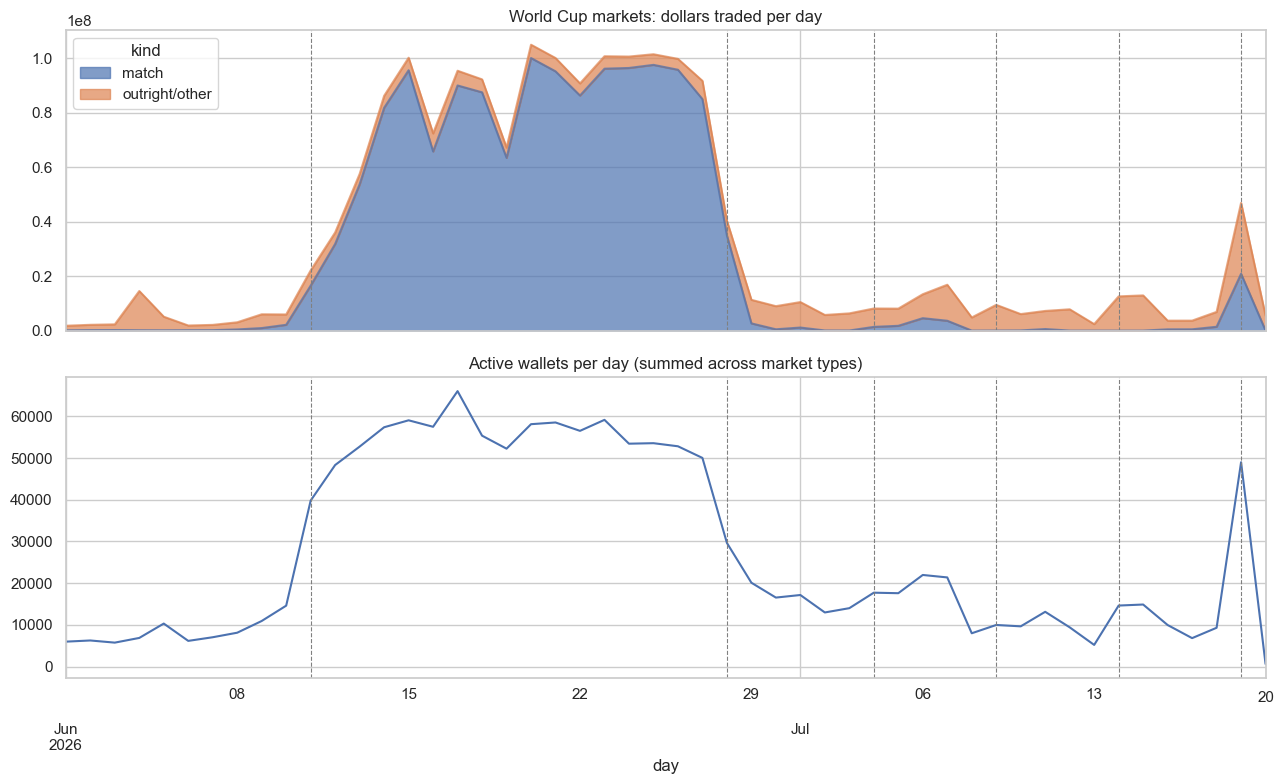

In [36]:
daily = con.execute("""
    SELECT CAST(ts AS DATE) AS day, kind, COUNT(*) AS fills,
           COUNT(DISTINCT wallet) AS wallets, SUM(dollars) AS usd
    FROM wc_trades GROUP BY 1, 2 ORDER BY 1, 2
""").df()
daily["day"] = pd.to_datetime(daily.day)

# Approximate stage start dates. Double-check against the official schedule.
milestones = {"Kickoff": "2026-06-11", "Round of 32": "2026-06-28", "Round of 16": "2026-07-04",
              "Quarterfinals": "2026-07-09", "Semifinals": "2026-07-14", "Final": "2026-07-19"}

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
daily.pivot(index="day", columns="kind", values="usd").fillna(0).plot.area(ax=ax[0], alpha=0.7)
ax[0].set_title("World Cup markets: dollars traded per day")
daily.groupby("day").wallets.sum().plot(ax=ax[1])
ax[1].set_title("Active wallets per day (summed across market types)")
for a in ax:
    for name, dte in milestones.items():
        a.axvline(pd.Timestamp(dte), ls="--", color="gray", lw=0.8)
plt.tight_layout(); plt.show()

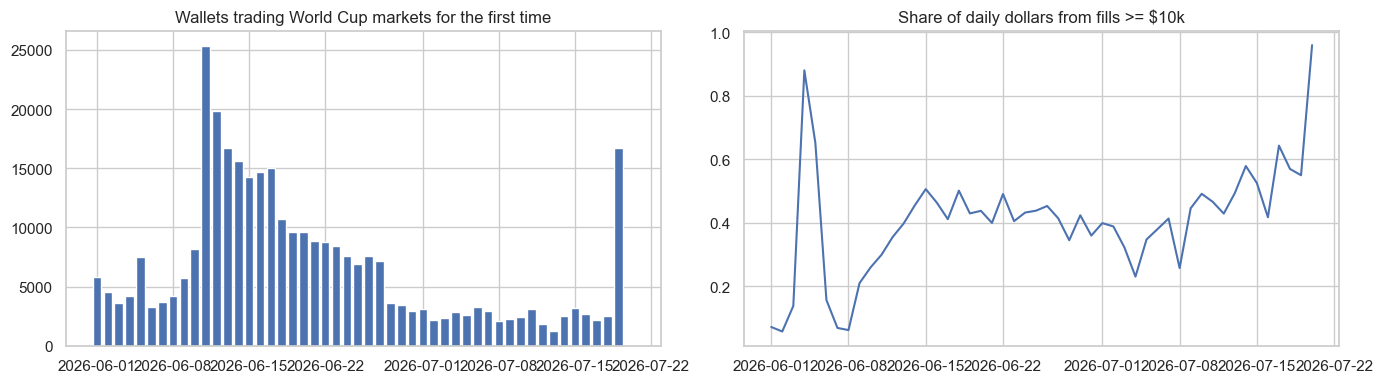

In [37]:
newcomers = con.execute("""
    SELECT first_day AS day, COUNT(*) AS new_wallets
    FROM (SELECT wallet, MIN(CAST(ts AS DATE)) AS first_day FROM wc_trades GROUP BY wallet)
    GROUP BY 1 ORDER BY 1
""").df()
whales = con.execute("""
    SELECT CAST(ts AS DATE) AS day,
           SUM(CASE WHEN dollars >= 10000 THEN dollars ELSE 0 END) / SUM(dollars) AS share_from_fills_over_10k
    FROM wc_trades GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(pd.to_datetime(newcomers.day), newcomers.new_wallets)
ax[0].set_title("Wallets trading World Cup markets for the first time")
ax[1].plot(pd.to_datetime(whales.day), whales.share_from_fills_over_10k)
ax[1].set_title("Share of daily dollars from fills >= $10k")
plt.tight_layout(); plt.show()

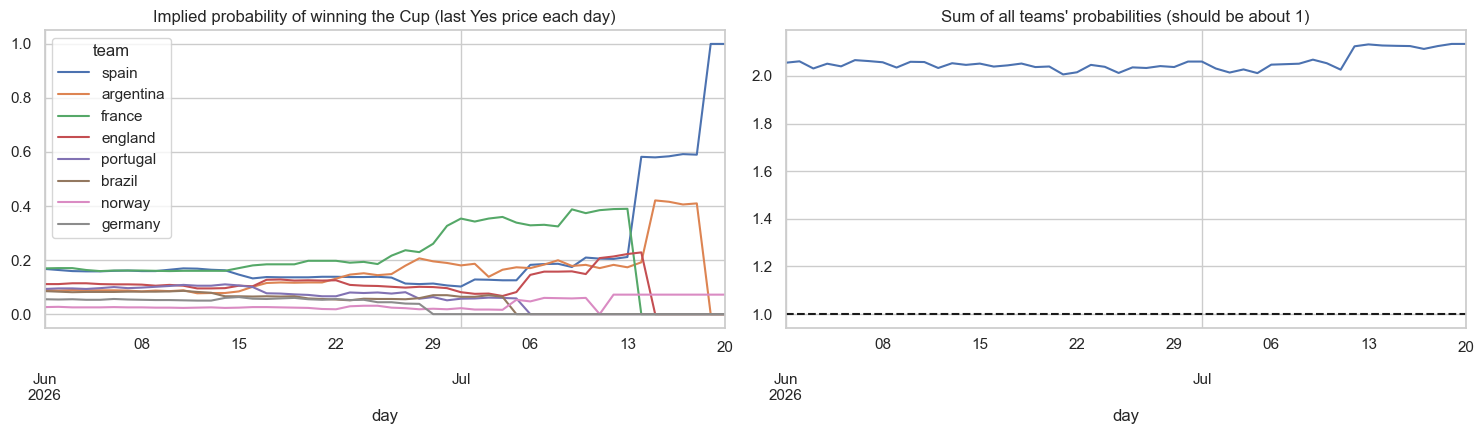

In [38]:
out = con.execute("""
    SELECT CAST(ts AS DATE) AS day, market, arg_max(price, ts) AS last_price, SUM(dollars) AS usd
    FROM wc_trades
    WHERE outcome = 'Yes' AND market LIKE '%-win-the-2026-fifa-world-cup%'
    GROUP BY 1, 2
""").df()
out["team"] = out.market.str.extract(r"will-(.+?)-win-the-2026-fifa-world-cup")[0]
out["day"] = pd.to_datetime(out.day)

prob = out.pivot(index="day", columns="team", values="last_price").sort_index().ffill()
top = out.groupby("team").usd.sum().nlargest(8).index

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
prob[top].plot(ax=ax[0]); ax[0].set_title("Implied probability of winning the Cup (last Yes price each day)")
prob.sum(axis=1).plot(ax=ax[1]); ax[1].axhline(1, ls="--", color="k")
ax[1].set_title("Sum of all teams' probabilities (should be about 1)")
plt.tight_layout(); plt.show()

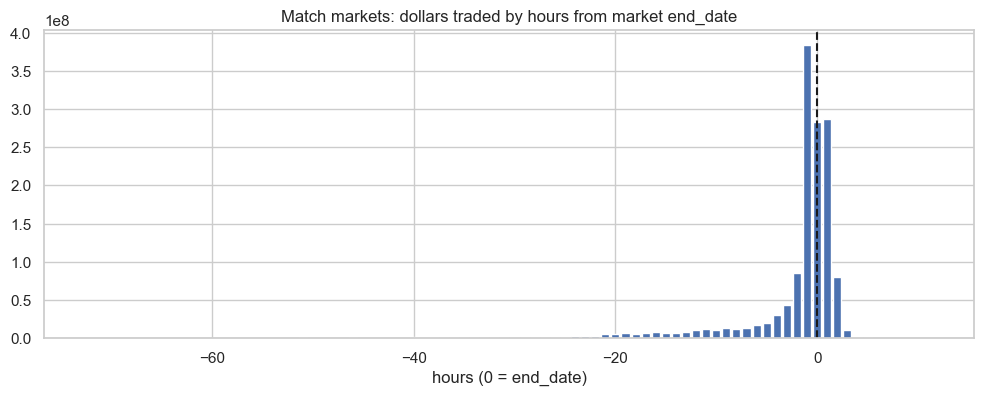

In [39]:
rel = con.execute("""
    SELECT FLOOR(epoch(ts - end_date) / 3600.0) AS hours_from_end_date,
           COUNT(*) AS fills, SUM(dollars) AS usd
    FROM wc_trades
    WHERE kind = 'match'
      AND ts BETWEEN end_date - INTERVAL 72 HOUR AND end_date + INTERVAL 12 HOUR
    GROUP BY 1 ORDER BY 1
""").df()
plt.figure(figsize=(12, 4))
plt.bar(rel.hours_from_end_date, rel.usd); plt.axvline(0, color="k", ls="--")
plt.title("Match markets: dollars traded by hours from market end_date")
plt.xlabel("hours (0 = end_date)"); plt.show()

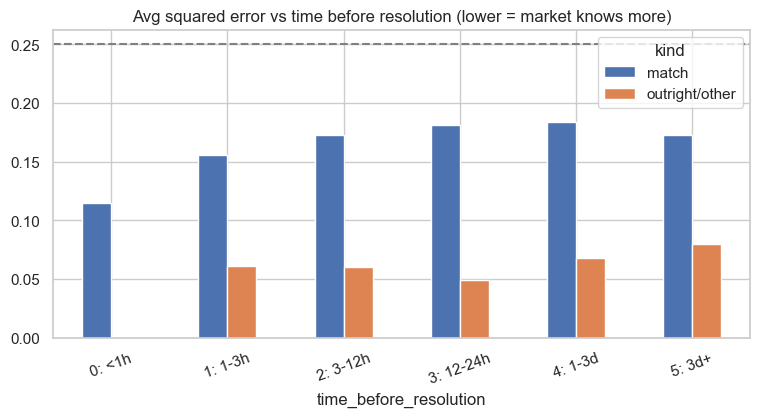

In [40]:
learn = con.execute("""
    SELECT CASE WHEN hrs_to_resolve < 1  THEN '0: <1h'
                WHEN hrs_to_resolve < 3  THEN '1: 1-3h'
                WHEN hrs_to_resolve < 12 THEN '2: 3-12h'
                WHEN hrs_to_resolve < 24 THEN '3: 12-24h'
                WHEN hrs_to_resolve < 72 THEN '4: 1-3d'
                ELSE '5: 3d+' END AS time_before_resolution,
           kind, COUNT(*) AS fills,
           AVG(POWER(bet_on_winner::INT - price, 2)) AS avg_squared_error
    FROM trades_enriched WHERE hrs_to_resolve >= 0
    GROUP BY 1, 2 ORDER BY 2, 1
""").df()
learn.pivot(index="time_before_resolution", columns="kind", values="avg_squared_error") \
     .plot.bar(rot=20, figsize=(9, 4))
plt.axhline(0.25, ls="--", color="gray")
plt.title("Avg squared error vs time before resolution (lower = market knows more)"); plt.show()

In [41]:
# Do we have knockout-stage match markets at all?
con.execute("""
    SELECT CAST(end_date AS DATE) AS day, COUNT(*) AS match_markets
    FROM wc_markets WHERE kind = 'match' GROUP BY 1 ORDER BY 1
""").df()

,day,match_markets
0,2026-06-11,190
1,2026-06-12,625
2,2026-06-13,1400
3,2026-06-14,2323
4,2026-06-15,1848
5,2026-06-16,1014
6,2026-06-17,1871
7,2026-06-18,1303
8,2026-06-19,938
9,2026-06-20,1150


In [42]:
q(text("SELECT slug, title FROM events WHERE title ILIKE '%world cup%' LIMIT 50"))

,slug,title
0,crint-ken-dnk-2026-10-21-team-top-batter,ICC Cricket World Cup Challenge League A: Keny...
1,crint-ken-dnk-2026-10-21-more-markets,ICC Cricket World Cup Challenge League A: Keny...
2,crint-ken-dnk-2026-10-21,ICC Cricket World Cup Challenge League A: Keny...
3,crint-kwt-qat-2026-10-05,T20 World Cup Asia Sub-Regional Qualifier A: K...
4,crint-btn-mmr-2026-10-04-most-sixes,T20 World Cup Asia Sub-Regional Qualifier A: B...
5,crint-nam-are-2026-10-03,Cricket World Cup League 2: Namibia vs UAE
6,crint-usa-nam-2026-10-07,Cricket World Cup League 2: USA vs Namibia
7,crint-usa-are-2026-10-05,Cricket World Cup League 2: USA vs UAE
8,crint-bhr-btn-2026-10-06,T20 World Cup Asia Sub-Regional Qualifier A: B...
9,crint-omn-can-2026-10-09-team-top-batter,Cricket World Cup League 2: Oman vs Canada - T...


In [43]:
con.execute("SELECT MAX(end_date) AS last_market_end FROM wc_markets").df()

,last_market_end
0,2026-08-31


In [44]:
import re

WINDOW_START = "2026-06-01"      # analysis window start (trades and market creation)

wcm = q(text("""
    SELECT slug, title, event_slug, outcomes, token_ids, start_date, end_date
    FROM markets
    WHERE slug LIKE 'fifwc-%' OR slug LIKE '%2026-fifa-world-cup%'
"""))
for c in ["start_date", "end_date"]:
    wcm[c] = pd.to_datetime(wcm[c], utc=True).dt.tz_localize(None)

as_list = lambda x: json.loads(x) if isinstance(x, str) else x
wcm["outcomes"]  = wcm.outcomes.map(as_list)
wcm["yes_token"] = wcm.token_ids.map(lambda x: (as_list(x) or [None])[0])

wcm = wcm.merge(res[["market_slug", "resolved_yes", "resolved_at"]],
                left_on="slug", right_on="market_slug", how="left")
wcm["winner_label"] = wcm.apply(
    lambda r: None if pd.isna(r.resolved_yes) or len(r.outcomes) < 2
    else (r.outcomes[0] if bool(r.resolved_yes) else r.outcomes[1]), axis=1)
wcm["kind"] = np.where(wcm.slug.str.startswith("fifwc-"), "match", "outright/other")

# --- category rules: a first guess, check the diagnostics below and adjust ---
GAME_RE = re.compile(r"^fifwc-([a-z0-9]+)-([a-z0-9]+)-(\d{4}-\d{2}-\d{2})-?(.*)$")

def game_cat(bet, game):
    teams = game.split("-")[:2]
    if re.search(r"exact-score|correct-score", bet):                                      return "Game: exact score"
    if re.search(r"^(goals?|assists?|shots?|cards?)-|scorer|assist|anytime|player", bet): return "Game: player props"
    if re.search(r"total|spread|over|under|o-u|handicap|btts|both-teams|corner", bet):    return "Game: totals/BTTS/spread"
    if bet in ("moneyline", "draw", "team-to-advance", "advance", "winner") or bet in teams or bet in [f"{t}-win" for t in teams]:
        return "Game: result/advance"
    return "Game: other (halftime, penalty shootout, ...)"

def classify(slug):
    s = slug.lower()
    m = GAME_RE.match(s)
    if m:
        bet = m.group(4) or "moneyline"
        game = f"{m.group(1)}-{m.group(2)}-{m.group(3)}"
        cat = game_cat(bet, game)
        return pd.Series(dict(scope="game", category=cat, game_key=game, bet_type=bet))
    if re.search(r"golden-boot|top-scorer|golden-ball|golden-glove|best-player|young-player|mvp|player-of", s):
        return pd.Series(dict(scope="player", category="Tournament player award", game_key=None, bet_type=None))
    if "-win-the-2026-fifa-world-cup" in s:
        return pd.Series(dict(scope="team", category="Team to win the Cup", game_key=None, bet_type=None))
    if re.search(r"group|advance|reach|qualif|round-of|quarter|semi|final|eliminat", s):
        return pd.Series(dict(scope="team", category="Stage / group markets", game_key=None, bet_type=None))
    return pd.Series(dict(scope="other", category="Other", game_key=None, bet_type=None))

wcm = pd.concat([wcm, wcm.slug.apply(classify)], axis=1)

meta_cols = ["slug", "title", "kind", "scope", "category", "game_key", "bet_type",
             "start_date", "end_date", "resolved_at", "winner_label", "yes_token"]
con.execute("SELECT 1").fetchall()      # clears any unfinished result so register() works
con.register("meta_df", wcm[meta_cols])
con.execute("CREATE OR REPLACE TABLE wc_meta AS SELECT * FROM meta_df")
con.unregister("meta_df")

# Diagnostics: do the categories make sense?
print(wcm.category.value_counts(), "\n")
print("Bet types seen in game markets:")
print(wcm[wcm.scope == "game"].bet_type.value_counts().head(25), "\n")
wcm[wcm.category == "Other"][["slug", "title"]].head(15)

category
Game: player props                               10540
Game: totals/BTTS/spread                          3728
Game: exact score                                 1241
Game: other (halftime, penalty shootout, ...)      971
Other                                              804
Stage / group markets                              683
Game: result/advance                               219
Tournament player award                             75
Team to win the Cup                                 54
Name: count, dtype: int64 

Bet types seen in game markets:
bet_type
btts                                75
exact-score-3-1                     74
total-1pt5                          74
exact-score-1-3                     74
exact-score-0-2                     74
exact-score-0-1                     74
halftime-result-away                74
exact-score-1-1                     73
exact-score-2-0                     73
exact-score-1-0                     73
second-half-result-home             7

,slug,title
71,will-lionel-messi-score-6-goals-during-the-202...,Will Lionel Messi score 6+ goals during the 20...
105,will-yahia-fofana-record-the-most-clean-sheets...,Will Yahia Fofana record the most clean sheets...
106,will-a-player-representing-new-zealand-be-the-...,Will a player representing New Zealand be the ...
135,will-new-zealand-score-the-most-goals-at-the-2...,Will New Zealand score the most goals at the 2...
136,will-michael-olise-be-the-top-goalscorer-at-th...,Will Michael Olise be the top goalscorer at th...
141,will-luka-modri-record-the-most-assists-at-the...,Will Luka Modrić record the most assists at th...
148,will-milan-borjan-record-the-most-clean-sheets...,Will Milan Borjan record the most clean sheets...
155,will-lamine-yamal-record-the-most-goal-contrib...,Will Lamine Yamal record the most goal contrib...
170,will-oliver-sail-record-the-most-clean-sheets-...,Will Oliver Sail record the most clean sheets ...
176,will-australia-score-the-most-goals-at-the-202...,Will Australia score the most goals at the 202...


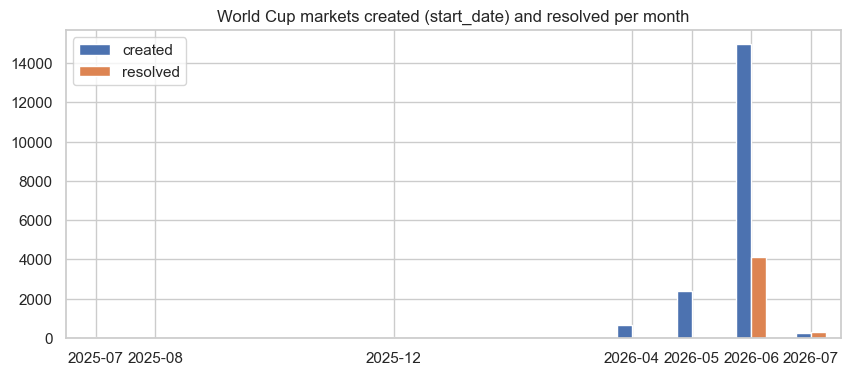

         created  resolved
2025-07       48         0
2025-08        1         0
2025-12       54         0
2026-04      661         0
2026-05     2387         0
2026-06    14944      4108
2026-07      220       287


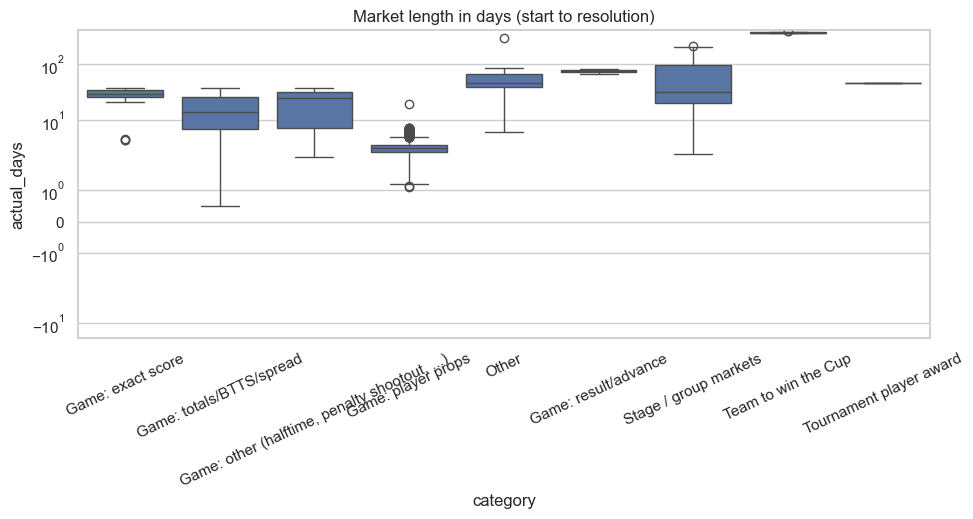

,markets,median_scheduled_days,median_actual_days,p90_actual_days
category,,,,
Game: exact score,1241,30.5,29.5,36.2
"Game: other (halftime, penalty shootout, ...)",971,9.1,24.4,35.4
Game: player props,10540,2.8,3.1,5.9
Game: result/advance,219,75.2,75.1,81.3
Game: totals/BTTS/spread,3728,9.1,13.9,30.7
Other,804,52.4,46.2,75.5
Stage / group markets,683,36.3,31.2,200.3
Team to win the Cup,54,382.1,364.0,374.2
Tournament player award,75,46.3,46.2,46.2


In [45]:
m = wcm.copy()
m["created_month"]  = m.start_date.dt.to_period("M")
m["resolved_month"] = m.resolved_at.dt.to_period("M")

months = (pd.DataFrame({"created": m.created_month.value_counts(),
                        "resolved": m.resolved_month.value_counts()})
            .fillna(0).astype(int).sort_index())
months.plot.bar(figsize=(10, 4), rot=0)
plt.title("World Cup markets created (start_date) and resolved per month"); plt.show()
print(months)

# Market length: scheduled (end - start) vs actual (resolved - start)
m["scheduled_days"] = (m.end_date - m.start_date).dt.total_seconds() / 86400
m["actual_days"]    = (m.resolved_at - m.start_date).dt.total_seconds() / 86400

length = m.groupby("category").agg(
    markets=("slug", "count"),
    median_scheduled_days=("scheduled_days", "median"),
    median_actual_days=("actual_days", "median"),
    p90_actual_days=("actual_days", lambda s: s.quantile(0.9)))

plt.figure(figsize=(11, 4))
sns.boxplot(data=m.dropna(subset=["actual_days"]), x="category", y="actual_days")
plt.yscale("symlog"); plt.xticks(rotation=25); plt.title("Market length in days (start to resolution)")
plt.show()
length.round(1)

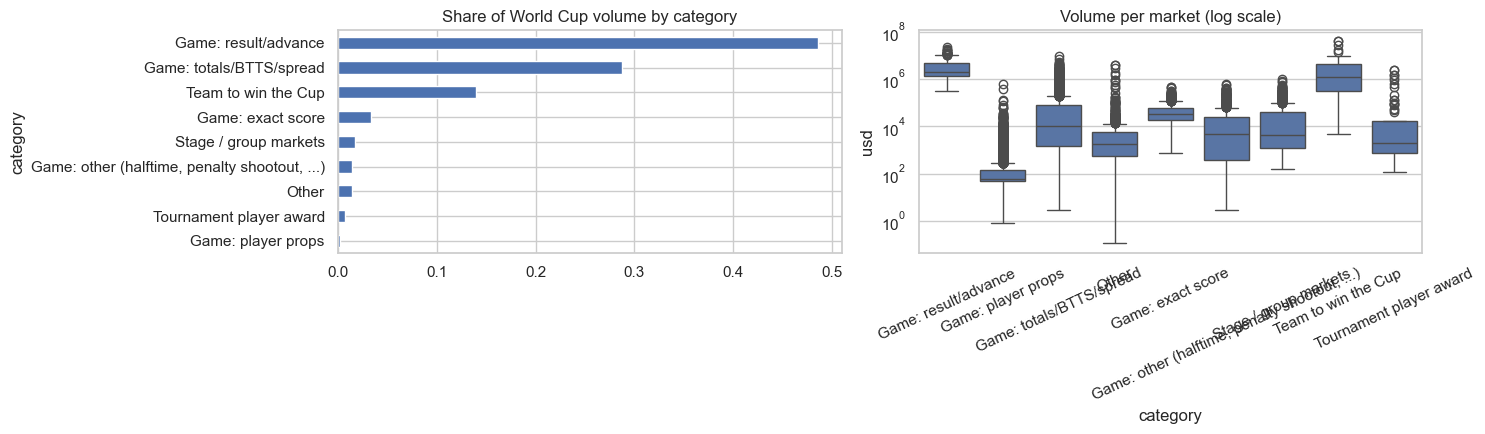

,markets,total_usd,mean_usd,median_usd,p90_usd,max_usd,share_of_volume
category,,,,,,,
Game: result/advance,219,8.365786e+08,3819993.675,1965558.081,9924145.241,2.248657e+07,0.485
Game: totals/BTTS/spread,3721,4.951233e+08,133061.890,10797.285,335506.327,8.975876e+06,0.287
Team to win the Cup,54,2.410886e+08,4464603.929,1166583.084,8913803.802,4.220559e+07,0.140
Game: exact score,1241,5.756287e+07,46384.262,33851.633,93740.283,4.806839e+05,0.033
Stage / group markets,683,2.916444e+07,42700.498,4226.307,119507.152,9.620757e+05,0.017
"Game: other (halftime, penalty shootout, ...)",892,2.422276e+07,27155.564,4910.335,68677.876,6.192483e+05,0.014
Other,797,2.390261e+07,29990.733,1805.827,18303.632,3.997596e+06,0.014
Tournament player award,75,1.169764e+07,155968.543,1889.935,350508.958,2.296103e+06,0.007
Game: player props,8243,4.346293e+06,527.271,59.096,449.414,6.187545e+05,0.003


In [46]:
meta = con.execute("SELECT * FROM wc_meta").df()

vol = con.execute(f"""
    SELECT market AS slug, SUM(dollars) AS usd, COUNT(*) AS fills, COUNT(DISTINCT wallet) AS wallets
    FROM wc_trades WHERE ts >= TIMESTAMP '{WINDOW_START}' GROUP BY market
""").df().merge(meta[["slug", "title", "category", "scope", "game_key", "bet_type", "kind"]],
                on="slug", how="left")

bycat = (vol.groupby("category").agg(
            markets=("slug", "count"), total_usd=("usd", "sum"), mean_usd=("usd", "mean"),
            median_usd=("usd", "median"), p90_usd=("usd", lambda s: s.quantile(0.9)), max_usd=("usd", "max"))
         .sort_values("total_usd", ascending=False))
bycat["share_of_volume"] = bycat.total_usd / bycat.total_usd.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
bycat.share_of_volume.sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Share of World Cup volume by category")
sns.boxplot(data=vol[vol.usd > 0], x="category", y="usd", ax=ax[1])
ax[1].set_yscale("log"); ax[1].tick_params(axis="x", rotation=25); ax[1].set_title("Volume per market (log scale)")
plt.tight_layout(); plt.show()
bycat.round(3)

In [47]:
# By game: all bet types on the same match rolled up
games = (vol[vol.scope == "game"].groupby("game_key")
            .agg(markets=("slug", "count"), usd=("usd", "sum"), fills=("fills", "sum"))
            .sort_values("usd", ascending=False))
print(f"{len(games)} games | median game volume ${games.usd.median():,.0f} | busiest game ${games.usd.iloc[0]:,.0f}")
display(games.head(15))

# By player: tournament awards + in-game player props
vol[vol.category.isin(["Tournament player award", "Game: player props"])] \
    .sort_values("usd", ascending=False)[["slug", "category", "usd", "fills", "wallets"]].head(15)

98 games | median game volume $15,428,641 | busiest game $33,811,466


,markets,usd,fills
game_key,,,
esp-cvi-2026-06-15,323,3.381147e+07,161994
mar-hai-2026-06-24,101,3.194522e+07,85701
arg-aut-2026-06-22,73,3.155364e+07,137914
ger-civ-2026-06-20,227,3.059157e+07,149993
bel-egy-2026-06-15,344,2.801998e+07,111707
jpn-swe-2026-06-25,80,2.748376e+07,103169
tur-usa-2026-06-25,81,2.735100e+07,119743
nor-fra-2026-06-26,82,2.666089e+07,122035
ecu-ger-2026-06-25,80,2.616011e+07,129054


,slug,category,usd,fills,wallets
10139,will-rodri-win-the-golden-ball-at-the-2026-fif...,Tournament player award,2.296103e+06,4848,701
7184,will-lamine-yamal-win-the-golden-ball-at-the-2...,Tournament player award,2.292307e+06,5152,795
10133,will-ousmane-dembele-win-the-golden-ball-at-th...,Tournament player award,1.541273e+06,1671,265
10120,will-kylian-mbappe-win-the-golden-ball-at-the-...,Tournament player award,1.444732e+06,8018,1376
4107,will-lionel-messi-win-the-golden-ball-at-the-2...,Tournament player award,1.102122e+06,11908,2013
11054,will-harry-kane-win-the-golden-ball-at-the-202...,Tournament player award,8.848742e+05,3812,534
13685,fifwc-nor-eng-2026-07-11-goals-erling-haaland-...,Game: player props,6.187545e+05,5675,3139
5105,will-jude-bellingham-win-the-golden-ball-at-th...,Tournament player award,5.977801e+05,2970,422
15077,will-pedri-win-the-golden-ball-at-the-2026-fif...,Tournament player award,4.435518e+05,803,112
8381,fifwc-prt-cdr-2026-06-17-goals-cristiano-ronal...,Game: player props,3.639468e+05,2523,1482


top 1% of markets (159) hold 59.9% of volume
top 5% of markets (796) hold 88.2% of volume
top 10% of markets (1,592) hold 94.4% of volume
top 1% of wallets (3,301) hold 85.7% of volume
top 5% of wallets (16,509) hold 95.0% of volume
top 10% of wallets (33,018) hold 97.5% of volume


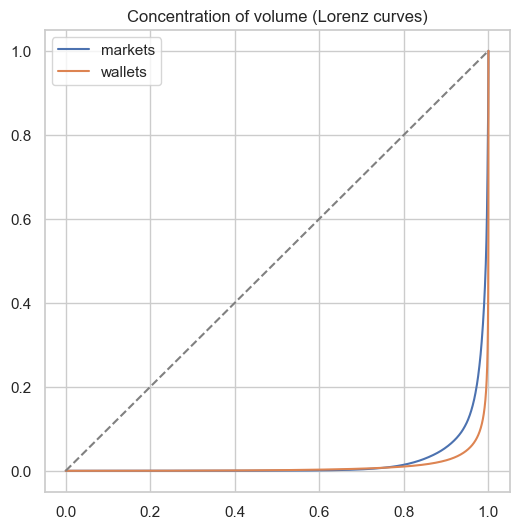

In [48]:
# Concentration: how much do the top 1% hold?
v = np.sort(vol.usd.values)[::-1]
for p in [0.01, 0.05, 0.10]:
    k = max(1, int(len(v) * p))
    print(f"top {p:.0%} of markets ({k:,}) hold {v[:k].sum() / v.sum():.1%} of volume")

w = (con.execute(f"SELECT SUM(dollars) AS usd FROM wc_trades WHERE ts >= TIMESTAMP '{WINDOW_START}' GROUP BY wallet")
        .df().usd.sort_values(ascending=False).values)
for p in [0.01, 0.05, 0.10]:
    k = max(1, int(len(w) * p))
    print(f"top {p:.0%} of wallets ({k:,}) hold {w[:k].sum() / w.sum():.1%} of volume")

def lorenz(x):
    xs = np.sort(x); c = np.cumsum(xs) / xs.sum()
    return np.linspace(0, 1, len(c)), c

plt.figure(figsize=(6, 6))
for name, arr in [("markets", vol.usd.values), ("wallets", w)]:
    xx, yy = lorenz(arr); plt.plot(xx, yy, label=name)
plt.plot([0, 1], [0, 1], "--", color="gray"); plt.legend()
plt.title("Concentration of volume (Lorenz curves)"); plt.show()

In [49]:
WINDOW_START, WINDOW_END = "2026-06-01", "2026-10-05 23:59:59"    # wallet trades end 2026-10-05
KNOCKOUT_START = "2026-06-28"                                     # Round of 32 starts (check the official schedule)

# --- map our categories onto the template's rows ---
def tmpl_cat(r):
    s = r.slug.lower()
    if r.category == "Game: result/advance":  return "Game winner"
    if r.category == "Team to win the Cup":   return "Tournament winner"
    if r.category == "Game: player props" or re.search(r"golden-boot|top-scorer", s):
        return "Player props (top scorer, etc.)"
    if r.category == "Tournament player award": return "Awards"
    return "Other"

wcm["tmpl_category"] = wcm.apply(tmpl_cat, axis=1)
wcm["game_date"] = pd.to_datetime(wcm.game_key.str[-10:], errors="coerce")
wcm["stage"] = np.where(wcm.game_date.isna(), None,
                np.where(wcm.game_date >= pd.Timestamp(KNOCKOUT_START), "Knockout games", "Group stage games"))

ws_, we_ = pd.Timestamp(WINDOW_START), pd.Timestamp(WINDOW_END)
life_end = wcm.resolved_at.fillna(wcm.end_date)
wcm["active_in_window"]   = (wcm.start_date <= we_) & (life_end >= ws_)
wcm["created_in_window"]  = wcm.start_date.between(ws_, we_)
wcm["resolved_in_window"] = wcm.resolved_at.between(ws_, we_)

meta_cols = ["slug", "title", "kind", "scope", "category", "tmpl_category", "stage", "game_key", "game_date",
             "bet_type", "start_date", "end_date", "resolved_at", "winner_label", "yes_token"]
con.execute("SELECT 1").fetchall()      # clears any unfinished result so register() works
con.register("meta_df", wcm[meta_cols])
con.execute("CREATE OR REPLACE TABLE wc_meta AS SELECT * FROM meta_df")
con.unregister("meta_df")

TW = f"ts BETWEEN TIMESTAMP '{WINDOW_START}' AND TIMESTAMP '{WINDOW_END}'"     # trade-window filter used below
print(wcm.tmpl_category.value_counts(), "\n", wcm.stage.value_counts(dropna=False))

tmpl_category
Player props (top scorer, etc.)    10543
Other                               7427
Game winner                          219
Awards                                72
Tournament winner                     54
Name: count, dtype: int64 
 stage
Group stage games    16466
NaN                   1616
Knockout games         233
Name: count, dtype: int64


In [50]:
vol_by_mkt = con.execute(f"""
    SELECT market AS slug, SUM(dollars) AS usd, COUNT(*) AS trades
    FROM wc_trades WHERE {TW} GROUP BY market
""").df()
traded = set(vol_by_mkt.slug)

ACTIVE_DEFINITION = "overlap"      # "overlap" = life overlaps the window | "traded" = at least one trade in the window
act  = wcm[wcm.slug.isin(traded)] if ACTIVE_DEFINITION == "traded" else wcm[wcm.active_in_window]
cr   = wcm[wcm.created_in_window]
dn   = wcm[wcm.resolved_in_window]
len_days = ((cr.resolved_at - cr.start_date).dt.total_seconds() / 86400).dropna()   # created in window AND resolved

tableA1 = pd.DataFrame([
    ["Markets active in window",  len(act), f"definition: {ACTIVE_DEFINITION}. Other counts: with >=1 trade in window = {len(traded):,}; life overlaps window = {int(wcm.active_in_window.sum()):,}; all World Cup markets matched = {len(wcm):,}"],
    ["Markets created in window", len(cr),  "start_date (scheduled open) inside the window"],
    ["Markets resolved in window", len(dn), "resolved_at inside the window"],
    ["Market length, median (days)", round(len_days.median(), 2), f"created in window and resolved (n={len(len_days):,}); resolved_at - start_date"],
    ["Market length, mean (days)",   round(len_days.mean(), 2),   "mean far above median = a few very long-lived markets"],
], columns=["Metric", "Value", "Notes"])

# category mix (volume = trades inside the window)
cm = act.merge(vol_by_mkt, on="slug", how="left").fillna({"usd": 0, "trades": 0})
order = ["Game winner", "Tournament winner", "Player props (top scorer, etc.)", "Awards", "Other"]
mix = cm.groupby("tmpl_category").agg(markets=("slug", "count"), usd=("usd", "sum")).reindex(order).fillna(0)
stage = (cm[cm.stage.notna()].groupby("stage").agg(markets=("slug", "count"), usd=("usd", "sum"))
           .reindex(["Group stage games", "Knockout games"]).fillna(0))
mix = pd.concat([mix, stage])
mix["% of markets"] = mix.markets / len(cm)
mix["% of volume"]  = mix.usd / cm.usd.sum()
tableA2 = mix.rename(columns={"markets": "# markets", "usd": "Volume (USD)"}).reset_index(names="World Cup category")

print("Group/Knockout rows are a different cut (all bet types on those games), so they overlap the rows above.")
display(tableA1); display(tableA2.round(3))

# What is inside "Other"? (exact score, totals/BTTS, halftime, stage markets, ...)
other = (cm[cm.tmpl_category == "Other"].groupby("category")
           .agg(markets=("slug", "count"), usd=("usd", "sum")).sort_values("usd", ascending=False))
other["% of all volume"] = other.usd / cm.usd.sum()
display(other.round(3))

Group/Knockout rows are a different cut (all bet types on those games), so they overlap the rows above.


,Metric,Value,Notes
0,Markets active in window,18237.00,definition: overlap. Other counts: with >=1 tr...
1,Markets created in window,15164.00,start_date (scheduled open) inside the window
2,Markets resolved in window,4395.00,resolved_at inside the window
3,"Market length, median (days)",4.02,"created in window and resolved (n=2,234); reso..."
4,"Market length, mean (days)",7.50,mean far above median = a few very long-lived ...


,World Cup category,# markets,Volume (USD),% of markets,% of volume
0,Game winner,219,8.365786e+08,0.012,0.487
1,Tournament winner,48,2.379793e+08,0.003,0.139
2,"Player props (top scorer, etc.)",10540,4.346293e+06,0.578,0.003
3,Awards,60,1.169053e+07,0.003,0.007
4,Other,7370,6.266538e+08,0.404,0.365
5,Group stage games,16466,1.378345e+09,0.903,0.803
6,Knockout games,233,3.948866e+07,0.013,0.023


,markets,usd,% of all volume
category,,,
Game: totals/BTTS/spread,3728,4.951233e+08,0.288
Game: exact score,1241,5.756287e+07,0.034
Stage / group markets,634,2.585386e+07,0.015
"Game: other (halftime, penalty shootout, ...)",971,2.422276e+07,0.014
Other,796,2.389102e+07,0.014


In [51]:
tot = con.execute(f"""
    SELECT COUNT(*) AS trades, SUM(dollars) AS usd, AVG(dollars) AS avg_usd, MEDIAN(dollars) AS med_usd
    FROM wc_trades WHERE {TW}
""").df().iloc[0]
v = np.sort(vol_by_mkt.usd.values)[::-1]
k = max(1, int(len(v) * 0.01))

tableB1 = pd.DataFrame([
    ["Total volume (USD)",     round(tot.usd, 0),     "sum of fills inside the window"],
    ["Total trades",           int(tot.trades),       "one row per fill"],
    ["Average trade size (USD)", round(tot.avg_usd, 2), ""],
    ["Median trade size (USD)",  round(tot.med_usd, 2), ""],
    ["Share of volume in top 1% of markets", round(v[:k].sum() / v.sum(), 4), f"top {k:,} of {len(v):,} markets that traded"],
], columns=["Metric", "Value", "Notes"])

# Around kickoff. end_date is about kickoff for match markets (volume peaks within an hour of it).
order = ["More than 7 days", "1-7 days", "6-24 hours", "1-6 hours", "Last hour", "In-play (after kickoff)"]
ko = con.execute(f"""
    SELECT CASE WHEN t.ts >= m.end_date THEN 'In-play (after kickoff)'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 1   THEN 'Last hour'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 6   THEN '1-6 hours'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 24  THEN '6-24 hours'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 168 THEN '1-7 days'
                ELSE 'More than 7 days' END AS bucket,
           SUM(t.dollars) AS usd
    FROM wc_trades t JOIN wc_meta m ON m.slug = t.market
    WHERE m.scope = 'game' AND t.{TW}
    GROUP BY 1
""").df().set_index("bucket").reindex(order).fillna(0)
ko["% of game volume"] = ko.usd / ko.usd.sum()
tableB2 = ko.rename(columns={"usd": "Volume (USD)"}).reset_index(names="Time before kickoff")

top10 = (vol_by_mkt.sort_values("usd", ascending=False).head(10).reset_index(drop=True))
top10.insert(0, "Rank", range(1, len(top10) + 1))
tableB3 = top10.rename(columns={"slug": "Slug", "usd": "Volume (USD)", "trades": "Trades"})

display(tableB1); display(tableB2.round(3)); display(tableB3)

,Metric,Value,Notes
0,Total volume (USD),1.723687e+09,sum of fills inside the window
1,Total trades,9.428974e+06,one row per fill
2,Average trade size (USD),1.828100e+02,
3,Median trade size (USD),9.700000e+00,
4,Share of volume in top 1% of markets,5.985000e-01,"top 159 of 15,925 markets that traded"


,Time before kickoff,Volume (USD),% of game volume
0,More than 7 days,2.551826e+06,0.002
1,1-7 days,3.676482e+07,0.026
2,6-24 hours,1.347076e+08,0.095
3,1-6 hours,1.953473e+08,0.138
4,Last hour,3.846410e+08,0.271
5,In-play (after kickoff),6.638213e+08,0.468


,Rank,Slug,Volume (USD),Trades
0,1,will-spain-win-the-2026-fifa-world-cup-963,4.220559e+07,134744
1,2,will-argentina-win-the-2026-fifa-world-cup-245,3.867466e+07,154421
2,3,will-france-win-the-2026-fifa-world-cup-924,2.801467e+07,152157
3,4,fifwc-esp-arg-2026-07-19-team-to-advance,2.248657e+07,67838
4,5,fifwc-bel-egy-2026-06-15-bel,1.844633e+07,31056
5,6,fifwc-tur-usa-2026-06-25-usa,1.719078e+07,57366
6,7,will-congo-dr-win-the-2026-fifa-world-cup,1.638311e+07,10255
7,8,fifwc-ger-civ-2026-06-20-ger,1.622328e+07,56367
8,9,fifwc-usa-par-2026-06-12-usa,1.561225e+07,52047
9,10,fifwc-jpn-swe-2026-06-25-jpn,1.511942e+07,34107


In [52]:
months = pd.period_range(WINDOW_START[:7], WINDOW_END[:7], freq="M")

tm = con.execute(f"""
    SELECT date_trunc('month', ts) AS month, COUNT(*) AS trades, SUM(dollars) AS usd, COUNT(DISTINCT wallet) AS traders
    FROM wc_trades WHERE {TW} GROUP BY 1
""").df()
tm["month"] = pd.to_datetime(tm.month).dt.to_period("M")
tm = tm.set_index("month")

created  = cr.start_date.dt.to_period("M").value_counts()
resolved = dn.resolved_at.dt.to_period("M").value_counts()

tableB4 = pd.DataFrame(index=months)
tableB4["Markets created"]  = created.reindex(months).fillna(0).astype(int)
tableB4["Markets resolved"] = resolved.reindex(months).fillna(0).astype(int)
tableB4["Trades"]           = tm.trades.reindex(months).fillna(0).astype(int)
tableB4["Volume (USD)"]     = tm.usd.reindex(months).fillna(0).round(0)
tableB4["Unique traders"]   = tm.traders.reindex(months).fillna(0).astype(int)
tableB4.index = [m.strftime("%b %Y") for m in months]
tableB4.index = [("Oct 1-5 2026" if i == "Oct 2026" else i) for i in tableB4.index]
tableB4 = tableB4.reset_index(names="Month")
print("Unique traders are distinct within each month, so the column does not add up to the total.")
tableB4

Unique traders are distinct within each month, so the column does not add up to the total.


,Month,Markets created,Markets resolved,Trades,Volume (USD),Unique traders
0,Jun 2026,14944,4108,8438113,1.525086e+09,267820
1,Jul 2026,220,287,990861,1.986007e+08,136795
2,Aug 2026,0,0,0,0.000000e+00,0
3,Sep 2026,0,0,0,0.000000e+00,0
4,Oct 1-5 2026,0,0,0,0.000000e+00,0


In [53]:
# Order book snapshots (replaces the earlier C5a loader: adds best-level size and number of price levels)
con.execute("DROP TABLE IF EXISTS wc_book"); con.execute("DROP TABLE IF EXISTS wc_book_loaded")    # run once: old table has fewer columns
con.execute("SET TimeZone = 'UTC'")
tokens = wcm[wcm.yes_token.notna()][["slug", "yes_token"]]
con.execute("SELECT 1").fetchall()
con.register("tok_df", tokens)
con.execute("CREATE OR REPLACE TABLE wc_tokens AS SELECT * FROM tok_df")
con.unregister("tok_df")

SNAP_HOURS = [18]          # UTC hours to sample per day (snapshot = book at the START of that hour)
SNAP_FIRST = WINDOW_START[:10]
SNAP_LAST  = str(min(we_, wcm.resolved_at.max()).date())     # no World Cup market is open after its last resolution
print("snapshots from", SNAP_FIRST, "to", SNAP_LAST)

con.execute("CREATE TABLE IF NOT EXISTS wc_book_loaded (hour VARCHAR)")
done = {r[0] for r in con.execute("SELECT hour FROM wc_book_loaded").fetchall()}
have_book = con.execute("SELECT COUNT(*) FROM information_schema.tables WHERE table_name = 'wc_book'").fetchone()[0] > 0

for d in pd.date_range(SNAP_FIRST, SNAP_LAST).strftime("%Y-%m-%d"):
    for h in SNAP_HOURS:
        hour = f"{d}T{h:02d}"
        if hour in done:
            continue
        url = f"{BASE}/snap-{hour}.parquet"
        sql = f"""
            WITH s AS (
                SELECT asset_id, ts_ms, bids, asks,
                       bids[1].price AS best_bid, asks[1].price AS best_ask,
                       bids[1].size  AS best_bid_size, asks[1].size AS best_ask_size,
                       len(bids) AS n_bid_levels, len(asks) AS n_ask_levels
                FROM read_parquet('{url}')
                WHERE asset_id IN (SELECT yes_token FROM wc_tokens)
            ),
            b AS (
                SELECT asset_id, SUM(lvl.size) AS bid_depth_5c
                FROM (SELECT asset_id, best_bid, unnest(bids) AS lvl FROM s)
                WHERE lvl.price >= best_bid - 0.05 GROUP BY asset_id
            ),
            a AS (
                SELECT asset_id, SUM(lvl.size) AS ask_depth_5c
                FROM (SELECT asset_id, best_ask, unnest(asks) AS lvl FROM s)
                WHERE lvl.price <= best_ask + 0.05 GROUP BY asset_id
            )
            SELECT s.asset_id, CAST(to_timestamp(s.ts_ms / 1000.0) AS TIMESTAMP) AS ts,
                   s.best_bid, s.best_ask, s.best_bid_size, s.best_ask_size, s.n_bid_levels, s.n_ask_levels,
                   b.bid_depth_5c, a.ask_depth_5c
            FROM s LEFT JOIN b ON b.asset_id = s.asset_id LEFT JOIN a ON a.asset_id = s.asset_id
        """
        try:
            if not have_book:
                con.execute(f"CREATE TABLE wc_book AS {sql}"); have_book = True
            else:
                con.execute(f"INSERT INTO wc_book {sql}")
            con.execute("INSERT INTO wc_book_loaded VALUES (?)", [hour])
            print(hour, "ok")
        except Exception as e:
            print(hour, "skipped:", str(e)[:90])

snapshots from 2026-06-01 to 2026-07-20
2026-06-01T18 ok
2026-06-02T18 ok
2026-06-03T18 ok
2026-06-04T18 ok
2026-06-05T18 ok
2026-06-06T18 ok
2026-06-07T18 ok
2026-06-08T18 ok
2026-06-09T18 ok
2026-06-10T18 ok
2026-06-11T18 ok
2026-06-12T18 ok
2026-06-13T18 ok
2026-06-14T18 ok
2026-06-15T18 ok
2026-06-16T18 skipped: HTTP Error: HTTP GET error on 'https://d1yyqbluk0oz0t.cloudfront.net/snap-2026-06-16T18.pa
2026-06-17T18 skipped: HTTP Error: HTTP GET error on 'https://d1yyqbluk0oz0t.cloudfront.net/snap-2026-06-17T18.pa
2026-06-18T18 skipped: HTTP Error: HTTP GET error on 'https://d1yyqbluk0oz0t.cloudfront.net/snap-2026-06-18T18.pa
2026-06-19T18 skipped: HTTP Error: HTTP GET error on 'https://d1yyqbluk0oz0t.cloudfront.net/snap-2026-06-19T18.pa
2026-06-20T18 ok
2026-06-21T18 ok
2026-06-22T18 ok
2026-06-23T18 ok
2026-06-24T18 ok
2026-06-25T18 ok
2026-06-26T18 ok
2026-06-27T18 ok
2026-06-28T18 ok
2026-06-29T18 ok
2026-06-30T18 ok
2026-07-01T18 ok
2026-07-02T18 ok
2026-07-03T18 ok
2026-07-04T

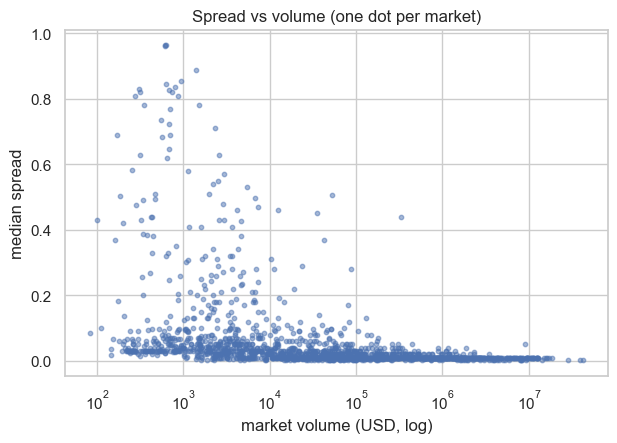

,Metric,Value,Notes
0,"Bid-ask spread, median",0.0200,"22,673 usable snapshots (live market, two-side..."
1,"Bid-ask spread, mean",0.0517,
2,"Depth: shares at best bid, median",126.5000,size at the single best price
3,"Depth: shares at best ask, median",134.0000,
4,"Depth: price levels per side, median",16.0000,bids 11 / asks 28
5,Spread vs. volume (correlation),-0.6370,"Spearman across 1,691 markets (median spread v..."


In [54]:
book = con.execute("""
    SELECT b.*, m.slug, m.start_date, m.end_date, m.resolved_at
    FROM wc_book b JOIN wc_tokens tk ON tk.yes_token = b.asset_id JOIN wc_meta m ON m.slug = tk.slug
""").df()
book["spread"] = book.best_ask - book.best_bid
book["mid"]    = (book.best_ask + book.best_bid) / 2
live = book[(book.ts >= book.start_date) & (book.ts <= book.resolved_at.fillna(book.end_date))
            & (book.spread >= 0) & book.mid.between(0.02, 0.98)
            & (book.ts >= ws_) & (book.ts <= we_)].copy()

mk = (live.groupby("slug").spread.median().rename("median_spread").reset_index().merge(vol_by_mkt, on="slug"))
rho = mk.usd.corr(mk.median_spread, method="spearman")

tableC1 = pd.DataFrame([
    ["Bid-ask spread, median", round(live.spread.median(), 4), f"{len(live):,} usable snapshots (live market, two-sided book, mid between 2c and 98c)"],
    ["Bid-ask spread, mean",   round(live.spread.mean(), 4),   ""],
    ["Depth: shares at best bid, median", round(live.best_bid_size.median(), 1), "size at the single best price"],
    ["Depth: shares at best ask, median", round(live.best_ask_size.median(), 1), ""],
    ["Depth: price levels per side, median", pd.concat([live.n_bid_levels, live.n_ask_levels]).median(),
        f"bids {live.n_bid_levels.median():.0f} / asks {live.n_ask_levels.median():.0f}"],
    ["Spread vs. volume (correlation)", round(rho, 3), f"Spearman across {len(mk):,} markets (median spread vs total volume); negative = busier markets are tighter"],
], columns=["Metric", "Value", "Notes"])

plt.figure(figsize=(7, 4.5)); plt.scatter(mk.usd, mk.median_spread, s=10, alpha=0.5)
plt.xscale("log"); plt.xlabel("market volume (USD, log)"); plt.ylabel("median spread"); plt.title("Spread vs volume (one dot per market)"); plt.show()
tableC1

In [55]:
labels = ["More than 30 days", "8-30 days", "2-7 days", "1-2 days", "Last 24 hours"]
edges  = [0, 24, 48, 168, 720, np.inf]          # hours before resolution

live["hrs_to_res"] = (live.resolved_at - live.ts).dt.total_seconds() / 3600
lv = live[live.hrs_to_res >= 0].copy()
lv["bucket"] = pd.cut(lv.hrs_to_res, bins=edges, labels=labels[::-1], right=False)
spread_by = lv.groupby("bucket", observed=False).spread.median().reindex(labels)

vb = con.execute(f"""
    SELECT CASE WHEN hrs_to_resolve < 24  THEN 'Last 24 hours'
                WHEN hrs_to_resolve < 48  THEN '1-2 days'
                WHEN hrs_to_resolve < 168 THEN '2-7 days'
                WHEN hrs_to_resolve < 720 THEN '8-30 days'
                ELSE 'More than 30 days' END AS bucket, SUM(dollars) AS usd
    FROM wc_trades WHERE hrs_to_resolve >= 0 AND {TW} GROUP BY 1
""").df().set_index("bucket").reindex(labels).fillna(0)

tableCD = pd.DataFrame({"Time until resolution": labels, "Median spread": spread_by.values.round(4),
                        "Volume (USD)": vb.usd.round(0).values})
tableCD["% of volume"] = (vb.usd / vb.usd.sum()).values
late = con.execute(f"SELECT SUM(dollars) FROM wc_trades WHERE hrs_to_resolve < 0 AND {TW}").fetchone()[0] or 0
print(f"Resolved markets only. Fills after the recorded resolution time (excluded): ${late:,.0f}")
tableCD.round(3)

Resolved markets only. Fills after the recorded resolution time (excluded): $239,967


,Time until resolution,Median spread,Volume (USD),% of volume
0,More than 30 days,0.01,2.201020e+07,0.016
1,8-30 days,0.01,1.270031e+08,0.093
2,2-7 days,0.01,7.074002e+07,0.052
3,1-2 days,0.01,3.058537e+07,0.022
4,Last 24 hours,0.01,1.116515e+09,0.817


Chart saved to: /Users/alainaliu/Documents/STATS 414/Midterm/wc_spread_variance.png


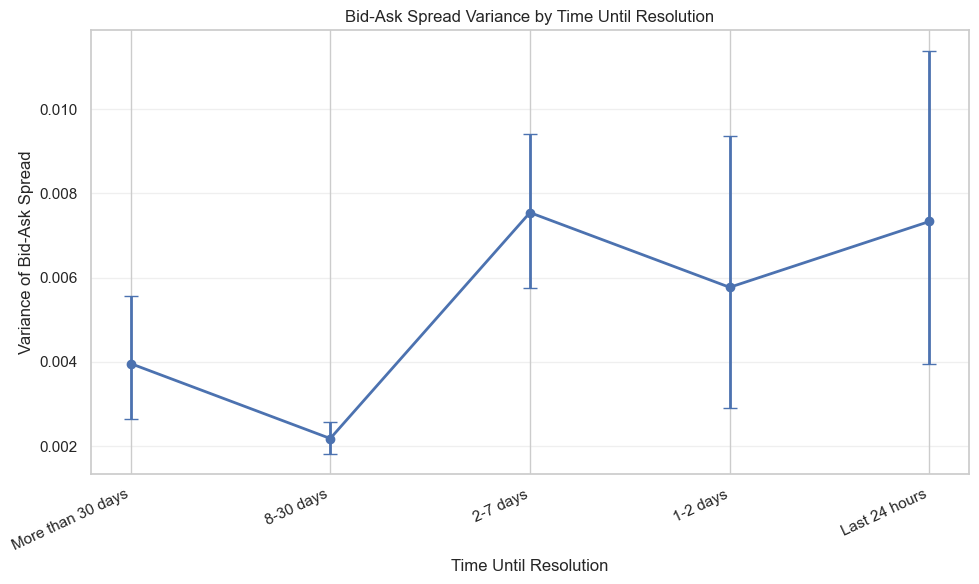

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Time-until-resolution buckets, ordered from earliest to latest
labels = [
    "More than 30 days",
    "8-30 days",
    "2-7 days",
    "1-2 days",
    "Last 24 hours"
]

# Ensure buckets follow the intended order
lv["bucket"] = pd.Categorical(
    lv["bucket"],
    categories=labels,
    ordered=True
)

# Bootstrap settings
rng = np.random.default_rng(42)
n_boot = 2000
results = []

# Calculate variance and 95% bootstrap confidence intervals
for bucket in labels:
    x = lv.loc[
        (lv["bucket"] == bucket) & lv["spread"].notna(),
        "spread"
    ].to_numpy()

    x = x[np.isfinite(x)]

    if len(x) < 2:
        results.append({
            "bucket": bucket,
            "variance": np.nan,
            "lower": np.nan,
            "upper": np.nan
        })
        continue

    observed_var = np.var(x, ddof=1)

    boot_vars = np.array([
        np.var(
            rng.choice(x, size=len(x), replace=True),
            ddof=1
        )
        for _ in range(n_boot)
    ])

    lower, upper = np.percentile(boot_vars, [2.5, 97.5])

    results.append({
        "bucket": bucket,
        "variance": observed_var,
        "lower": lower,
        "upper": upper
    })

# Store results in a DataFrame
variance_df = pd.DataFrame(results)

# Prepare error bar sizes
x_pos = np.arange(len(labels))
y = variance_df["variance"].to_numpy()
lower_error = y - variance_df["lower"].to_numpy()
upper_error = variance_df["upper"].to_numpy() - y

# Plot variance with 95% confidence intervals
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    x_pos,
    y,
    yerr=np.array([lower_error, upper_error]),
    fmt="-o",
    capsize=5,
    linewidth=2,
    markersize=6
)

ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_xlabel("Time Until Resolution")
ax.set_ylabel("Variance of Bid-Ask Spread")
ax.set_title("Bid-Ask Spread Variance by Time Until Resolution")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

# Save PNG to the current working directory
output_path = Path.cwd() / "wc_spread_variance.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Chart saved to: {output_path}")

plt.show()

# Trader Behavior

In [56]:

# --- Load ALL Polymarket trades for the study window ---
# This is separate from wc_trades, which only contains World Cup trades.

WSTART = "2026-06-01"
WEND = "2026-10-06"  # exclusive: includes all of Oct 5

con.execute("SET TimeZone = 'UTC'")
con.execute("CREATE TABLE IF NOT EXISTS all_loaded_days (day VARCHAR)")

done_days = {
    r[0] for r in con.execute("SELECT day FROM all_loaded_days").fetchall()
}
has_all_trades = (
    con.execute("""
        SELECT COUNT(*) FROM information_schema.tables
        WHERE table_name = 'all_trades'
    """).fetchone()[0] > 0
)

for day in pd.date_range(WSTART, "2026-10-05").strftime("%Y-%m-%d"):
    if day in done_days:
        continue

    url = f"{BASE}/wallet_trades/trades-{day}.parquet"

    sql = f"""
        SELECT
            t.wallet,
            t.market,
            CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP) AS ts,
            t.side,
            t.outcome,
            t.price,
            t.size,
            t.dollars
        FROM read_parquet('{url}') t
        WHERE CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP)
              >= TIMESTAMP '{WSTART}'
          AND CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP)
              < TIMESTAMP '{WEND}'
    """

    try:
        if not has_all_trades:
            con.execute(f"CREATE TABLE all_trades AS {sql}")
            has_all_trades = True
        else:
            con.execute(f"INSERT INTO all_trades {sql}")

        con.execute("INSERT INTO all_loaded_days VALUES (?)", [day])
        print(day, "loaded")
    except Exception as e:
        print(day, "skipped:", str(e)[:150])

# Check date coverage and loaded trade count
print(
    "Successfully loaded days:",
    con.execute("SELECT COUNT(*) FROM all_loaded_days").fetchone()[0]
)
display(con.execute("""
    SELECT COUNT(*) AS fills,
           COUNT(DISTINCT wallet) AS wallets,
           MIN(ts) AS first_trade,
           MAX(ts) AS last_trade
    FROM all_trades
""").df())


2026-06-01 loaded
2026-06-02 loaded
2026-06-03 loaded
2026-06-04 loaded
2026-06-05 loaded
2026-06-06 loaded
2026-06-07 loaded
2026-06-08 loaded
2026-06-09 loaded
2026-06-10 loaded
2026-06-11 loaded
2026-06-12 loaded
2026-06-13 loaded
2026-06-14 loaded
2026-06-15 loaded
2026-06-16 loaded
2026-06-17 loaded
2026-06-18 loaded
2026-06-19 loaded
2026-06-20 loaded
2026-06-21 loaded
2026-06-22 loaded
2026-06-23 loaded
2026-06-24 loaded
2026-06-25 loaded
2026-06-26 loaded
2026-06-27 loaded
2026-06-28 loaded
2026-06-29 loaded
2026-06-30 loaded
2026-07-01 loaded
2026-07-02 loaded
2026-07-03 loaded
2026-07-04 loaded
2026-07-05 loaded
2026-07-06 loaded
2026-07-07 loaded
2026-07-08 loaded
2026-07-09 loaded
2026-07-10 loaded
2026-07-11 loaded
2026-07-12 loaded
2026-07-13 loaded
2026-07-14 loaded
2026-07-15 loaded
2026-07-16 loaded
2026-07-17 loaded
2026-07-18 loaded
2026-07-19 loaded
2026-07-20 loaded
2026-07-21 loaded
2026-07-22 loaded
2026-07-23 loaded
2026-07-24 loaded
2026-07-25 loaded
2026-07-26

,fills,wallets,first_trade,last_trade
0,107102798,875572,2026-06-01 00:00:01,2026-10-05 23:59:58


,Metric,Value
0,Unique traders (wallets),330181.000
1,Share of volume from top 1% of wallets,85.704
2,Gini coefficient (volume per wallet),0.979
3,% of trades under $10,54.810
4,"% of trades over $1,000",2.222
5,% one-time traders (1 World Cup trade),26.810
6,"Markets per trader, median",2.000


,fills,volume_usd,% of fills,% of volume
trade_size_bucket,,,,
$0–<$1,1064603,7.998597e+05,11.29,0.05
$1–<$10,4103462,1.912614e+07,43.52,1.11
$10–<$100,3084261,1.173712e+08,32.71,6.81
"$100–<$1,000",965992,3.093119e+08,10.24,17.94
"$1,000+",210656,1.277078e+09,2.23,74.09


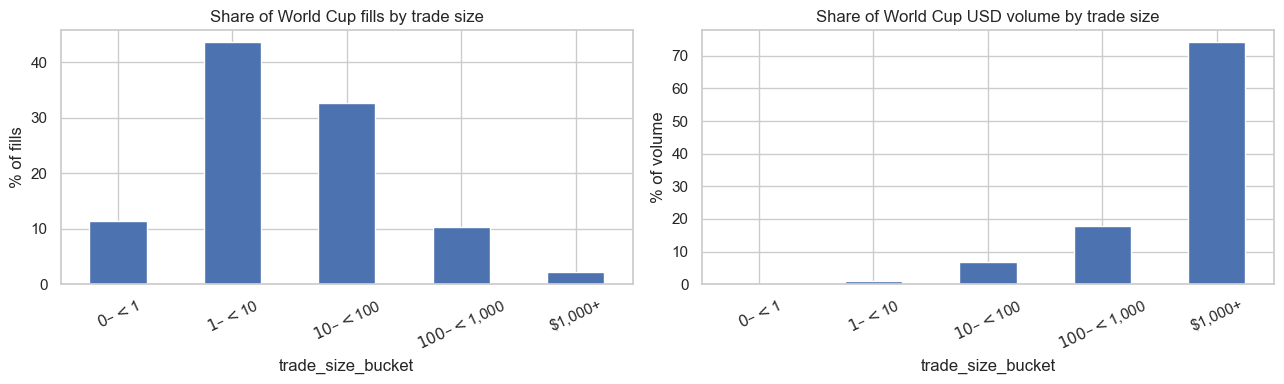

In [57]:

# --- Trader behavior: World Cup trades only ---

wc_window = con.execute(f"""
    SELECT wallet, market, ts, side, outcome, price, size, dollars
    FROM wc_trades
    WHERE ts >= TIMESTAMP '{WSTART}'
      AND ts <  TIMESTAMP '{WEND}'
""").df()

wc_window["dollars"] = pd.to_numeric(wc_window["dollars"], errors="coerce")
wc_window = wc_window.dropna(subset=["wallet", "market", "dollars"])
wc_window = wc_window[wc_window["dollars"] >= 0].copy()

# Wallet-level statistics
wallet_stats_wc = (
    wc_window.groupby("wallet")
    .agg(
        volume_usd=("dollars", "sum"),
        n_trades=("market", "size"),
        n_markets=("market", "nunique")
    )
    .sort_values("volume_usd", ascending=False)
)

n_wallets = len(wallet_stats_wc)
total_volume = wallet_stats_wc["volume_usd"].sum()
top1_n = max(1, int(np.ceil(n_wallets * 0.01)))

top1_volume_share = (
    wallet_stats_wc["volume_usd"].head(top1_n).sum() / total_volume
    if total_volume > 0 else np.nan
)

# Gini coefficient of wallet trading volume
def gini_coefficient(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0 or x.sum() <= 0:
        return np.nan
    if np.any(x < 0):
        raise ValueError("Gini input must be nonnegative.")
    x = np.sort(x)
    n = len(x)
    return (2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n

gini_volume = gini_coefficient(wallet_stats_wc["volume_usd"])

# Trade-level size thresholds
n_fills = len(wc_window)
pct_under_10 = (wc_window["dollars"] < 10).mean() * 100 if n_fills else np.nan
pct_over_1000 = (wc_window["dollars"] > 1000).mean() * 100 if n_fills else np.nan
pct_one_time = (wallet_stats_wc["n_trades"] == 1).mean() * 100 if n_wallets else np.nan

table_trader_behavior = pd.DataFrame([
    ["Unique traders (wallets)", n_wallets],
    ["Share of volume from top 1% of wallets", top1_volume_share * 100],
    ["Gini coefficient (volume per wallet)", gini_volume],
    ["% of trades under $10", pct_under_10],
    ["% of trades over $1,000", pct_over_1000],
    ["% one-time traders (1 World Cup trade)", pct_one_time],
    ["Markets per trader, median", wallet_stats_wc["n_markets"].median()],
], columns=["Metric", "Value"])

display(table_trader_behavior.round(3))

# Trade-size distribution: number of fills and USD volume by bucket
bins = [0, 1, 10, 100, 1000, np.inf]
labels = ["$0–<$1", "$1–<$10", "$10–<$100", "$100–<$1,000", "$1,000+"]

positive_trades = wc_window[wc_window["dollars"] > 0].copy()
positive_trades["trade_size_bucket"] = pd.cut(
    positive_trades["dollars"],
    bins=bins,
    labels=labels,
    right=False
)

trade_size_dist = (
    positive_trades.groupby("trade_size_bucket", observed=False)
    .agg(
        fills=("dollars", "size"),
        volume_usd=("dollars", "sum")
    )
)
trade_size_dist["% of fills"] = (
    trade_size_dist["fills"] / trade_size_dist["fills"].sum() * 100
)
trade_size_dist["% of volume"] = (
    trade_size_dist["volume_usd"] / trade_size_dist["volume_usd"].sum() * 100
)

display(trade_size_dist.round(2))

# Visualize trade-size distribution
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
trade_size_dist["% of fills"].plot.bar(ax=ax[0], rot=25)
ax[0].set_title("Share of World Cup fills by trade size")
ax[0].set_ylabel("% of fills")

trade_size_dist["% of volume"].plot.bar(ax=ax[1], rot=25)
ax[1].set_title("Share of World Cup USD volume by trade size")
ax[1].set_ylabel("% of volume")

plt.tight_layout()
plt.show()


In [58]:

# --- Cross-market overlap ---

overlap = con.execute(f"""
    WITH wc_wallets AS (
        SELECT DISTINCT wallet
        FROM wc_trades
        WHERE ts >= TIMESTAMP '{WSTART}'
          AND ts <  TIMESTAMP '{WEND}'
    ),
    other_wallets AS (
        SELECT DISTINCT t.wallet
        FROM all_trades t
        JOIN wc_wallets w ON t.wallet = w.wallet
        LEFT JOIN wc_meta m ON t.market = m.slug
        WHERE t.ts >= TIMESTAMP '{WSTART}'
          AND t.ts <  TIMESTAMP '{WEND}'
          AND m.slug IS NULL
    ),
    first_ts AS (
        SELECT wallet, MIN(ts) AS first_ts
        FROM all_trades
        WHERE ts >= TIMESTAMP '{WSTART}'
          AND ts <  TIMESTAMP '{WEND}'
        GROUP BY wallet
    ),
    first_trade_type AS (
        SELECT f.wallet,
               MAX(CASE WHEN m.slug IS NOT NULL THEN 1 ELSE 0 END) AS first_ts_includes_wc
        FROM first_ts f
        JOIN all_trades t
          ON t.wallet = f.wallet AND t.ts = f.first_ts
        LEFT JOIN wc_meta m ON t.market = m.slug
        GROUP BY f.wallet
    )
    SELECT
        (SELECT COUNT(*) FROM wc_wallets) AS wc_wallets,
        (SELECT COUNT(*) FROM other_wallets) AS wc_wallets_also_traded_other,
        (SELECT COUNT(*)
         FROM first_trade_type f
         JOIN wc_wallets w ON f.wallet = w.wallet
         WHERE f.first_ts_includes_wc = 1) AS wc_wallets_first_timestamp_wc
""").df()

n_wc = int(overlap.loc[0, "wc_wallets"])
n_other = int(overlap.loc[0, "wc_wallets_also_traded_other"])
n_first_wc = int(overlap.loc[0, "wc_wallets_first_timestamp_wc"])

table_overlap = pd.DataFrame([
    ["World Cup traders who also traded other markets",
     n_other,
     100 * n_other / n_wc if n_wc else np.nan],
    ["World Cup traders whose first observed trade timestamp included a World Cup market",
     n_first_wc,
     100 * n_first_wc / n_wc if n_wc else np.nan],
], columns=["Metric", "Wallets", "% of World Cup traders"])

print(f"World Cup traders in window: {n_wc:,}")
display(table_overlap.round(2))


World Cup traders in window: 330,181


,Metric,Wallets,% of World Cup traders
0,World Cup traders who also traded other markets,215417,65.24
1,World Cup traders whose first observed trade t...,193276,58.54


In [59]:

# --- Profitability proxy: resolved World Cup positions only ---
# This is an estimate, not complete lifetime P&L.

resolved_wallet_pnl = con.execute(f"""
    WITH positions AS (
        SELECT
            wallet,
            market,
            outcome,
            SUM(CASE WHEN side = 'BUY'  THEN size ELSE 0 END) AS buy_shares,
            SUM(CASE WHEN side = 'SELL' THEN size ELSE 0 END) AS sell_shares,
            SUM(CASE WHEN side = 'BUY'  THEN dollars ELSE 0 END) AS buy_usd,
            SUM(CASE WHEN side = 'SELL' THEN dollars ELSE 0 END) AS sell_usd,
            MAX(CAST(bet_on_winner AS INTEGER)) AS won
        FROM wc_trades
        WHERE ts >= TIMESTAMP '{WSTART}'
          AND ts <  TIMESTAMP '{WEND}'
          AND bet_on_winner IS NOT NULL
        GROUP BY wallet, market, outcome
    )
    SELECT
        wallet,
        SUM(buy_usd + sell_usd) AS volume_usd,
        SUM(
            won * (buy_shares - sell_shares)
            - buy_usd + sell_usd
        ) AS pnl_usd
    FROM positions
    WHERE buy_shares > 0
      AND sell_shares <= buy_shares
    GROUP BY wallet
    HAVING SUM(buy_usd + sell_usd) > 0
""").df()

resolved_wallet_pnl = resolved_wallet_pnl.sort_values(
    "volume_usd", ascending=False
).reset_index(drop=True)

n = len(resolved_wallet_pnl)
k1 = int(np.ceil(n * 0.01))
k10 = int(np.ceil(n * 0.10))

# Define non-overlapping groups by volume rank
resolved_wallet_pnl["trader_group"] = "Bottom 90%"
resolved_wallet_pnl.loc[:k10 - 1, "trader_group"] = "Next 9%"
resolved_wallet_pnl.loc[:k1 - 1, "trader_group"] = "Top 1%"

# Handle the case where no wallets qualify
if n == 0:
    table_profitability = pd.DataFrame(
        columns=[
            "Trader group (by volume)", "# wallets",
            "Volume (USD)", "Profit (USD)", "Profit per $1 traded"
        ]
    )
else:
    group_order = ["Top 1%", "Next 9%", "Bottom 90%"]

    table_profitability = (
        resolved_wallet_pnl.groupby("trader_group")
        .agg(
            wallets=("wallet", "nunique"),
            volume_usd=("volume_usd", "sum"),
            profit_usd=("pnl_usd", "sum")
        )
        .reindex(group_order)
        .fillna(0)
    )

    table_profitability["profit_per_dollar"] = (
        table_profitability["profit_usd"]
        / table_profitability["volume_usd"].replace(0, np.nan)
    )

    table_profitability = table_profitability.reset_index()
    table_profitability = table_profitability.rename(columns={
        "trader_group": "Trader group (by volume)",
        "wallets": "# wallets",
        "volume_usd": "Volume (USD)",
        "profit_usd": "Profit (USD)",
        "profit_per_dollar": "Profit per $1 traded"
    })

display(table_profitability.round(4))


,Trader group (by volume),# wallets,Volume (USD),Profit (USD),Profit per $1 traded
0,Top 1%,2875,1.055779e+09,4.181383e+07,0.0396
1,Next 9%,25874,1.481143e+08,-7.313623e+06,-0.0494
2,Bottom 90%,258733,3.455005e+07,-4.933239e+06,-0.1428


In [62]:

# --- Export results to CSV files for Canva ---

from pathlib import Path

# Save to the current notebook working directory
OUTPUT_DIR = Path.cwd()
print(f"Saving CSV files to: {OUTPUT_DIR}")

# Each table gets its own CSV so it is easy to upload to Canva
exports = {
    "wc_trader_behavior.csv": "table_trader_behavior",
    "wc_trade_size_distribution.csv": "trade_size_dist",
    "wc_cross_market_overlap.csv": "table_overlap",
    "wc_profitability_by_volume.csv": "table_profitability",
}

saved_files = []

for filename, variable_name in exports.items():
    if variable_name not in globals():
        print(f"Skipped {filename}: run the cell defining {variable_name} first.")
        continue

    result = globals()[variable_name].copy()

    # Make index values, such as trade-size buckets, into a CSV column
    if result.index.name is not None or not isinstance(result.index, pd.RangeIndex):
        result = result.reset_index()

    filepath = OUTPUT_DIR / filename
    result.to_csv(filepath, index=False)
    saved_files.append(filepath)

    print(f"Saved: {filepath}")

print(f"\nSuccessfully exported {len(saved_files)} CSV files.")


Saving CSV files to: /Users/alainaliu/Documents/STATS 414/Midterm
Saved: /Users/alainaliu/Documents/STATS 414/Midterm/wc_trader_behavior.csv
Saved: /Users/alainaliu/Documents/STATS 414/Midterm/wc_trade_size_distribution.csv
Saved: /Users/alainaliu/Documents/STATS 414/Midterm/wc_cross_market_overlap.csv
Saved: /Users/alainaliu/Documents/STATS 414/Midterm/wc_profitability_by_volume.csv

Successfully exported 4 CSV files.
